# Intelligent Predictive Maintenance & Machine Failure Risk Management

## 1. Problem Statement

Unexpected machine failures in manufacturing industries can interrupt production, increase maintenance costs, delay deliveries, and reduce operational efficiency.

Traditional preventive maintenance relies on fixed schedules, which may result in unnecessary servicing or unexpected failures between inspections.

To address this challenge, we propose an **AI-powered Predictive Maintenance System** that analyzes historical machine operating conditions to predict potential failures and support proactive maintenance decisions.

## 2. Business Objectives

- Predict potential machine failures using operational data.
- Identify machine conditions associated with failures.
- Develop and compare traditional ML and ANN models.
- Minimize missed failures while controlling unnecessary inspections.
- Support maintenance teams through data-driven risk prioritization.

## 3. CBIM Approach – Context, Business, Implementation and Measurement

### C – Context
Understand manufacturing challenges, including unexpected machine failures, production interruptions, and increasing maintenance costs.

### B – Business
Define the business objective of predicting machine failures early, reducing downtime risks, and improving maintenance planning.

### I – Implementation
Develop an end-to-end solution using the AI4I 2020 dataset through:
- Data understanding, quality assessment, and EDA.
- Data preprocessing and feature engineering.
- Logistic Regression, Random Forest, and ANN development.
- Model comparison and controlled experimentation.
- Failure-risk classification and maintenance prioritization.

### M – Measurement
Evaluate model reliability using Precision, Recall, F1-score, ROC-AUC, PR-AUC, and Confusion Matrix.

Special attention will be given to **Recall**, as missing an actual machine failure can result in unexpected production downtime.

## 4. Dataset Overview

- Dataset: AI4I 2020 Predictive Maintenance Dataset
- Records: 10,000
- Columns: 14
- Problem Type: Binary Classification
- Target: `Machine failure` (0 = No Failure, 1 = Failure)

Identifier columns (`UDI`, `Product ID`) and failure-mode indicators (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) will be excluded from model inputs to prevent data leakage.

Dataset Source: https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

## 5. Expected Outcome

Develop a reliable and reproducible predictive maintenance solution that identifies potential machine failures, compares ML and ANN performance, and recommends an appropriate model to support proactive maintenance and improve manufacturing efficiency.

# Phase 1 — Business Understanding, Data Audit and Preparation

In [1]:
# Purpose: Import the required libraries and load the predictive maintenance dataset.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload the dataset
uploaded = files.upload()

# Load the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Display the dataset
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Saving ai4i2020.csv to ai4i2020.csv
Dataset loaded successfully!
Dataset Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1. Dataset Overview

The AI4I 2020 Predictive Maintenance Dataset is used to develop a machine failure prediction system for manufacturing operations.

The dataset contains 10,000 records and 14 columns, including machine operating conditions, product information, a binary machine failure target, and five failure-mode indicators.

The objective is to identify patterns in machine operating conditions and predict potential failures before they occur.

**Target Variable:** `Machine failure`
- 0 – No machine failure
- 1 – Machine failure

**Important consideration:** UDI and Product ID are identifiers, while TWF, HDF, PWF, OSF, and RNF are failure-mode indicators. These columns will be excluded from model training to prevent data leakage.

In [2]:
# Purpose: Inspect dataset dimensions, column names, data types, and sample records.

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (10000, 14)

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Initial Dataset Inspection

The dataset contains **10,000 records and 14 columns**, representing machine operating conditions, product information, and failure indicators.

The initial inspection reveals:

- 3 numerical columns with `float64` data type.
- 9 integer columns with `int64` data type.
- 2 categorical columns with `object` data type.
- All 10,000 records contain non-null values across all columns.
- The dataset occupies approximately 1.1 MB of memory.

The dataset contains both numerical and categorical features, which will require appropriate preprocessing before model development.

**Note:** Although no missing values are observed in this initial inspection, we will perform additional data-quality checks, including duplicate records, target imbalance, and unusual values.

In [3]:
# Checking data quality

# Purpose: Identify missing values, duplicate records, and duplicate columns.

print("Missing Values:")
display(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nDuplicate Column Names:", df.columns.duplicated().sum())

Missing Values:


,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Total Missing Values: 0

Duplicate Records: 0

Duplicate Column Names: 0


## 3. Data Quality Assessment

The initial data-quality assessment confirms that:

- **Missing Values:** No missing values were identified across the 14 columns.
- **Duplicate Records:** No duplicate rows were found.
- **Duplicate Columns:** No duplicate column names were detected.

The dataset appears structurally clean, so no missing-value imputation or duplicate removal is required at this stage.

However, further validation is necessary to identify potential outliers, unusual values, class imbalance, and possible data leakage before model development.

,Count,Percentage
Machine failure,,
0,9661,96.61
1,339,3.39


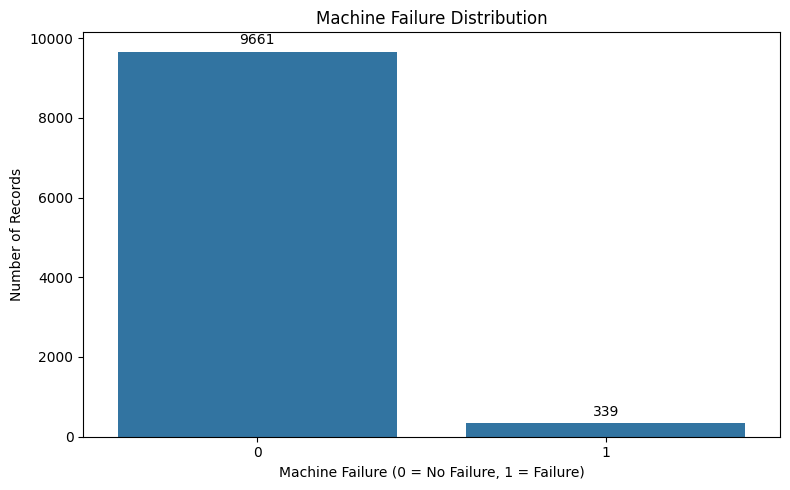

In [4]:
# Purpose: Analyze machine failure distribution and identify class imbalance.

failure_counts = df["Machine failure"].value_counts().sort_index()
failure_percentages = df["Machine failure"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": failure_counts,
    "Percentage": failure_percentages
})

display(target_summary)

# Visualize target distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x="Machine failure")

# Add count labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

## 4. Target Variable Distribution

The target variable `Machine failure` shows a significant class imbalance.

- **No Failure (0):** 9,661 records (96.61%).
- **Failure (1):** 339 records (3.39%).

The dataset is highly imbalanced, with failure cases representing only a small proportion of observations.

**Business implication:** A model that predicts every machine as operational could achieve 96.61% accuracy while failing to identify any actual machine failures.

Therefore, accuracy alone is not a reliable evaluation metric. We will prioritize Recall, Precision, F1-score, and PR-AUC to assess failure detection performance.

We will also investigate suitable class-imbalance handling techniques during model development.

In [5]:
# Purpose: Analyze the distribution of numerical operating parameters.

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Display descriptive statistics
display(df[numerical_features].describe())

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


## 5. Numerical Feature Analysis

The descriptive statistics provide an overview of the five machine operating parameters.

Key observations:

- **Air Temperature:** Mean of 300.00 K, with relatively low variation.
- **Process Temperature:** Mean of 310.01 K, indicating stable temperature measurements.
- **Rotational Speed:** Mean of 1538.78 rpm, with a maximum of 2886 rpm.
- **Torque:** Mean of 39.99 Nm, with values ranging from 3.8 to 76.6 Nm.
- **Tool Wear:** Mean of 107.95 minutes, ranging from 0 to 253 minutes.

The numerical features have different measurement scales and distributions. This will be considered during preprocessing, particularly when preparing data for Logistic Regression and ANN.

The maximum rotational speed and other extreme values will be investigated further rather than automatically treated as errors.

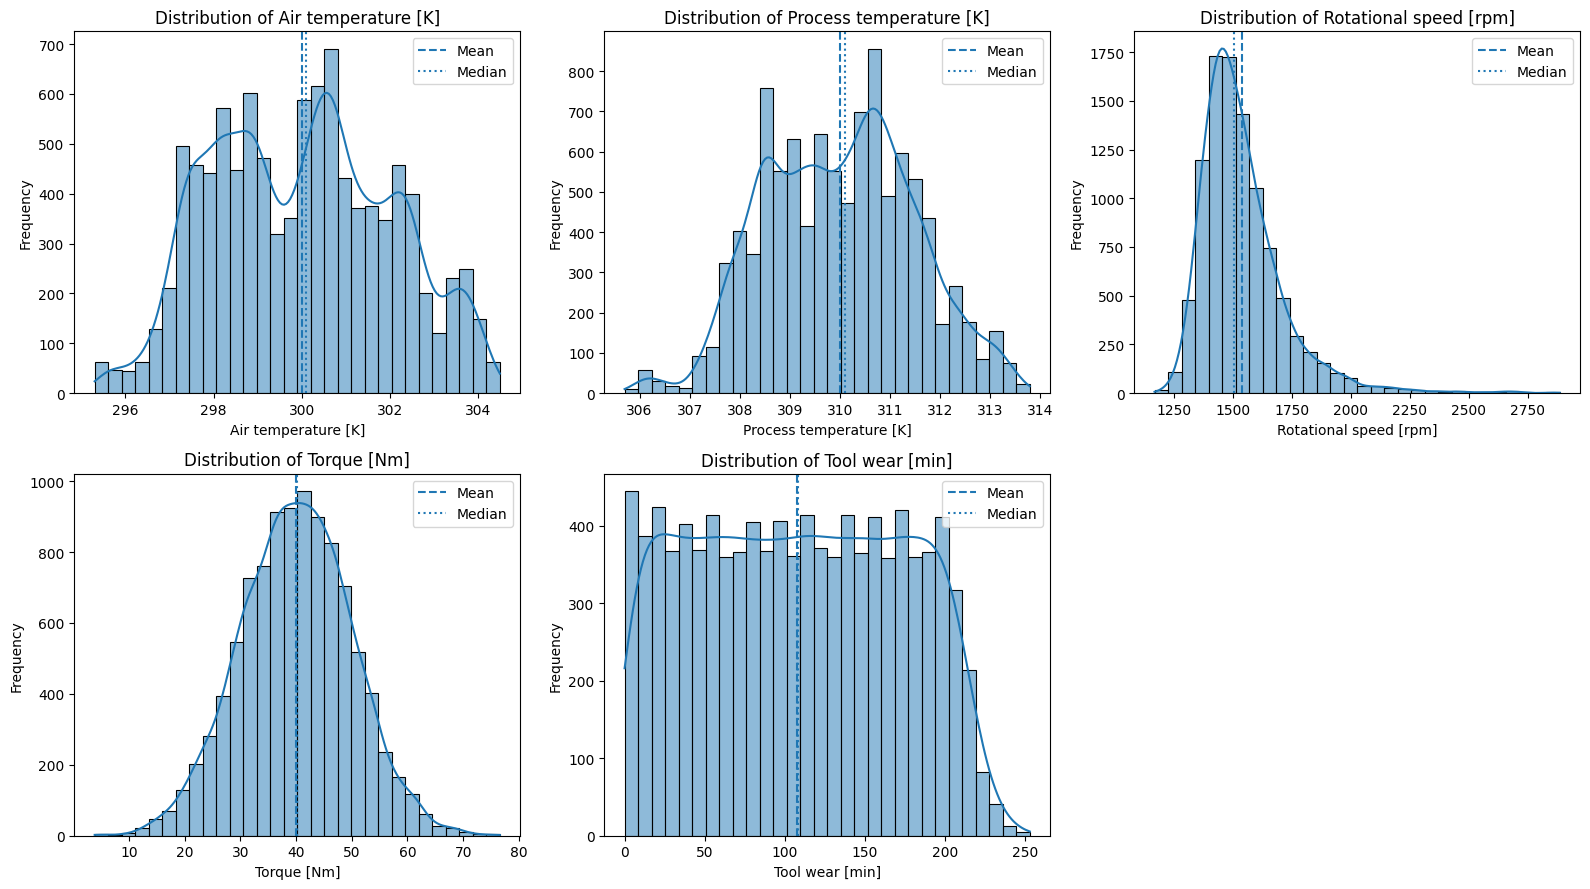

In [6]:
# Visualize numerical feature distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(numerical_features):
    sns.histplot(data=df, x=column, bins=30, kde=True, ax=axes[i])

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

    # Add mean and median reference lines
    axes[i].axvline(df[column].mean(), linestyle="--", label="Mean")
    axes[i].axvline(df[column].median(), linestyle=":", label="Median")
    axes[i].legend()

# Remove unused subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

In [7]:
# Hidden missing-value detection

# Purpose: Identify hidden missing-value representations in the dataset.

missing_tokens = [
    "", " ", "NA", "N/A", "NaN", "nan", "NAN",
    "NULL", "null", "None", "none", "?"
]

hidden_missing = {}

for column in df.columns:
    if df[column].dtype == "object":

        values = df[column].astype("string").str.strip()

        count = values.isin(missing_tokens).sum()

        if count > 0:
            hidden_missing[column] = count

print("Hidden Missing Values:")

if hidden_missing:
    display(pd.Series(hidden_missing, name="Count"))
else:
    print("No hidden missing-value representations found.")

print("\nTotal Hidden Missing Values:", sum(hidden_missing.values()))

Hidden Missing Values:
No hidden missing-value representations found.

Total Hidden Missing Values: 0


## Hidden Missing-Value Detection

Standard null checks may not identify missing values represented as text, such as `NA`, `N/A`, `NaN`, `NULL`, `None`, question marks, or empty strings.

To address this, additional validation was performed on categorical columns by checking for common hidden missing-value representations.

**Findings:**
- Hidden missing values detected: 0
- No suspicious missing-value tokens were found.

**Conclusion:** No hidden missing-value representations were identified. Therefore, no additional missing-value cleaning is required at this stage.

In [8]:
import re

# Purpose: Detect hidden missing values using regex patterns.

missing_pattern = re.compile(
    r"^\s*(?:"
    r"na|n/a|nan|null|none|"
    r"missing|not available|not applicable|"
    r"undefined|unknown|"
    r"[-]+|[?]+|"
    r"0|"
    r")\s*$",
    flags=re.IGNORECASE
)

hidden_missing_results = {}

for column in df.columns:

    if df[column].dtype == "object" or pd.api.types.is_string_dtype(df[column]):

        values = df[column].astype("string")

        matches = values.str.fullmatch(missing_pattern, na=False)

        if matches.any():
            hidden_missing_results[column] = {
                "Count": int(matches.sum()),
                "Values": values[matches].unique().tolist()
            }

print("REGEX-BASED HIDDEN MISSING VALUE AUDIT")
print("-" * 50)

if hidden_missing_results:
    for column, result in hidden_missing_results.items():
        print(f"\nColumn: {column}")
        print(f"Count: {result['Count']}")
        print(f"Values: {result['Values']}")
else:
    print("No regex-based hidden missing values detected.")

print("\nTotal Hidden Missing Values:",
      sum(x["Count"] for x in hidden_missing_results.values()))

REGEX-BASED HIDDEN MISSING VALUE AUDIT
--------------------------------------------------
No regex-based hidden missing values detected.

Total Hidden Missing Values: 0


## 4. Advanced Hidden Missing-Value Detection Using Regex

To strengthen the data-quality assessment, Regular Expressions (Regex) were used to identify hidden missing-value representations that may not be detected through standard null checks.

The validation covered common representations such as:
- NA, N/A, NaN and NULL
- None and Undefined
- Missing and Unknown
- Empty strings, question marks, and placeholder dashes

**Findings:**
- Regex-based hidden missing values: 0
- No suspicious missing-value representations were detected in the categorical columns.

**Conclusion:** Both standard and regex-based checks indicate that the dataset contains no detectable missing-value representations. No missing-value treatment is required.

In [9]:
# Outlier detection using IQR

# Purpose: Quantify potential outliers using the Interquartile Range (IQR) method.

outlier_results = []

for column in numerical_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Air temperature [K],293.50,306.30,0,0.00
1,Process temperature [K],305.35,314.55,0,0.00
2,Rotational speed [rpm],1139.50,1895.50,418,4.18
3,Torque [Nm],12.80,67.20,69,0.69
4,Tool wear [min],-110.50,325.50,0,0.00


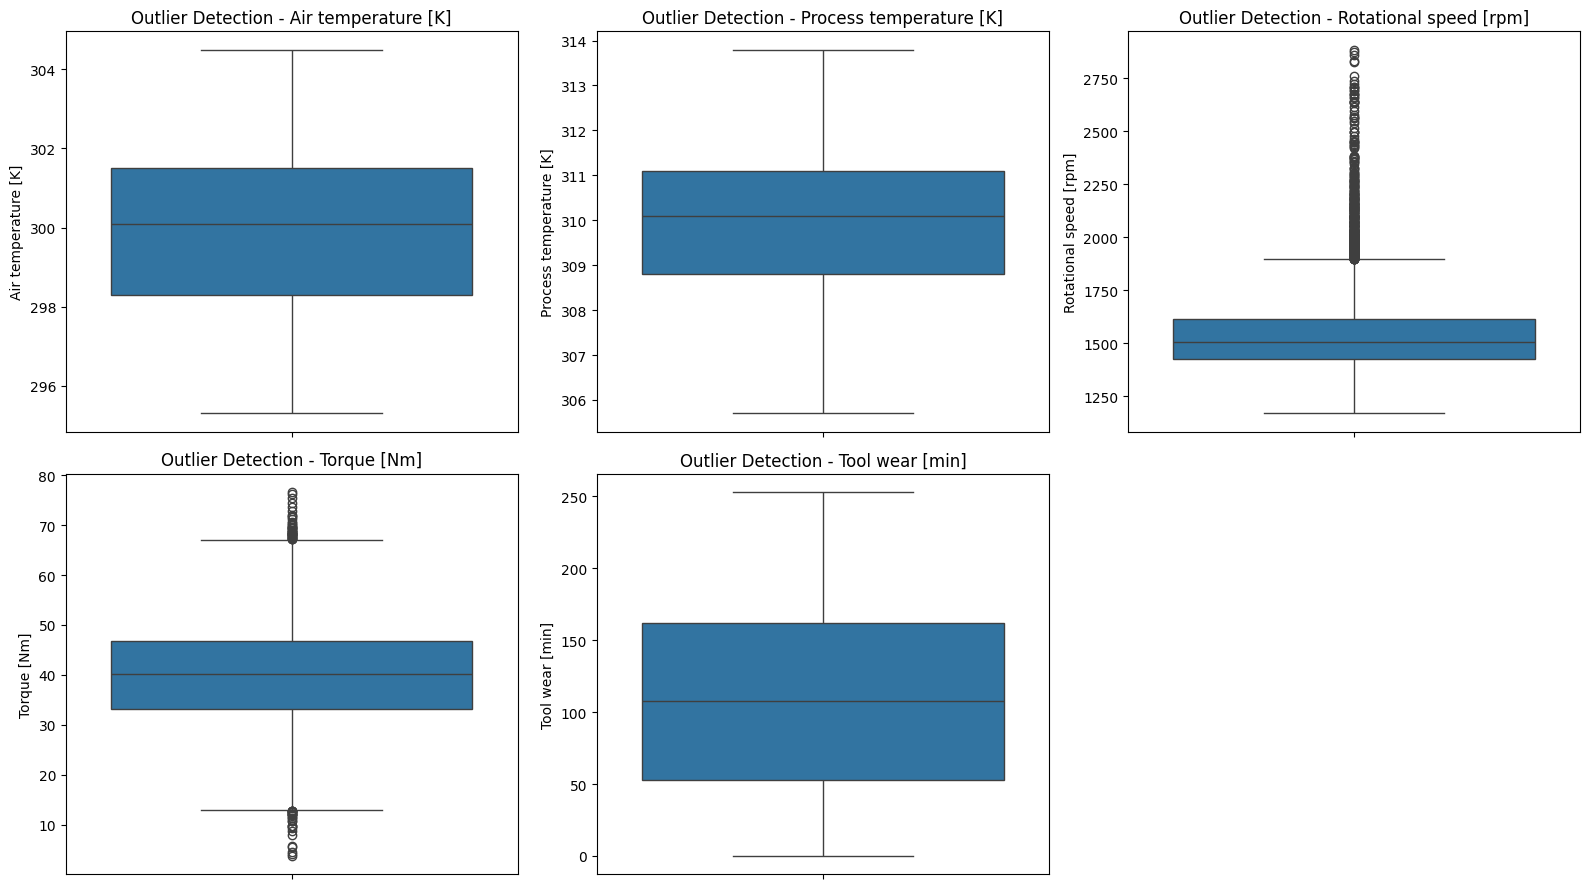

In [10]:
# Outlier detection using boxplots

# Purpose: Visualize potential outliers in numerical operating parameters.

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(numerical_features):

    sns.boxplot(y=df[column], ax=axes[i])

    axes[i].set_title(f"Outlier Detection - {column}")
    axes[i].set_ylabel(column)

plt.delaxes(axes[5])

plt.tight_layout()
plt.show()

## Outlier Analysis and Treatment Decision

The IQR method identified potential outliers in Rotational Speed and Torque, while Air Temperature, Process Temperature, and Tool Wear showed no outliers.

Key findings:
- Rotational Speed: 418 outliers (4.18%).
- Torque: 69 outliers (0.69%).
- Other numerical features: No detected outliers.

These extreme observations may represent genuine machine operating conditions rather than data-entry errors.

**Treatment Decision:**

We will retain the identified outliers at this stage instead of automatically removing or capping them.

Since unusual rotational speeds and torque levels may contain useful information about machine failure conditions, their relationship with the target variable will be investigated before making any treatment decisions.

In [11]:
# Outliers against machine failure

# Purpose: Examine the relationship between potential outliers and machine failures.

outlier_features = ["Rotational speed [rpm]", "Torque [Nm]"]

outlier_comparison = []

for column in outlier_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    for status, mask in [
        ("Outlier", outlier_mask),
        ("Normal", ~outlier_mask)
    ]:

        total = mask.sum()
        failures = df.loc[mask, "Machine failure"].sum()

        outlier_comparison.append({
            "Feature": column,
            "Group": status,
            "Records": total,
            "Failures": failures,
            "Failure Rate (%)": round(
                failures / total * 100, 2
            ) if total > 0 else 0
        })

comparison_df = pd.DataFrame(outlier_comparison)

display(comparison_df)

,Feature,Group,Records,Failures,Failure Rate (%)
0,Rotational speed [rpm],Outlier,418,35,8.37
1,Rotational speed [rpm],Normal,9582,304,3.17
2,Torque [Nm],Outlier,69,62,89.86
3,Torque [Nm],Normal,9931,277,2.79


## Outlier Relationship with Machine Failure

To understand whether extreme operating conditions are associated with machine failures, the detected outliers were compared against normal observations.

**Key Findings:**

1. **Rotational Speed:**
   - Outlier failure rate: 8.37%.
   - Normal observation failure rate: 3.17%.
   - Outlier observations show a higher failure rate than normal observations.

2. **Torque:**
   - Outlier failure rate: 89.86%.
   - Normal observation failure rate: 2.79%.
   - Torque outliers show a significantly higher failure rate.

**Interpretation:**

Extreme rotational speeds and torque measurements may contain valuable information for identifying potential machine failures. The relationship is particularly strong for torque outliers.

**Treatment Decision:**

We will retain these observations without removing or capping them, as they may represent meaningful machine operating conditions.

These findings indicate statistical associations, not proof that extreme values directly cause machine failures.

In [12]:
# Analyze lower and upper outliers separately

# Purpose: Compare failure rates across lower, normal, and upper operating ranges.

directional_results = []

for column in outlier_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    conditions = [
        df[column] < lower_bound,
        df[column] > upper_bound
    ]

    groups = ["Lower Outlier", "Upper Outlier"]

    for condition, group in zip(conditions, groups):

        subset = df[condition]

        directional_results.append({
            "Feature": column,
            "Group": group,
            "Records": len(subset),
            "Failures": subset["Machine failure"].sum(),
            "Failure Rate (%)": round(
                subset["Machine failure"].mean() * 100, 2
            ) if len(subset) > 0 else 0
        })

    normal = df[
        (df[column] >= lower_bound) &
        (df[column] <= upper_bound)
    ]

    directional_results.append({
        "Feature": column,
        "Group": "Normal",
        "Records": len(normal),
        "Failures": normal["Machine failure"].sum(),
        "Failure Rate (%)": round(
            normal["Machine failure"].mean() * 100, 2
        )
    })

directional_summary = pd.DataFrame(directional_results)

display(directional_summary)

,Feature,Group,Records,Failures,Failure Rate (%)
0,Rotational speed [rpm],Lower Outlier,0,0,0.00
1,Rotational speed [rpm],Upper Outlier,418,35,8.37
2,Rotational speed [rpm],Normal,9582,304,3.17
3,Torque [Nm],Lower Outlier,28,25,89.29
4,Torque [Nm],Upper Outlier,41,37,90.24
5,Torque [Nm],Normal,9931,277,2.79


## Directional Outlier Analysis

The lower and upper outliers were analyzed separately to understand their relationship with machine failures.

**Key Findings:**

1. **Rotational Speed:**
   - No lower outliers were detected.
   - Upper outliers: 418 records, with an 8.37% failure rate.
   - Normal observations: 3.17% failure rate.

2. **Torque:**
   - Lower outliers: 28 records, with an 89.29% failure rate.
   - Upper outliers: 41 records, with a 90.24% failure rate.
   - Normal observations: 2.79% failure rate.

**Interpretation:**

Both unusually low and high torque measurements show a significantly higher association with machine failures. Upper rotational-speed outliers also show an increased failure rate.

**Final Treatment Decision:**

All identified outliers will be retained because they may represent meaningful abnormal machine operating conditions.

Removing or capping these observations could eliminate valuable failure-related information and negatively affect model performance.

,Type,Records,Failures,Failure_Rate
0,H,1003,21,2.09
1,L,6000,235,3.92
2,M,2997,83,2.77


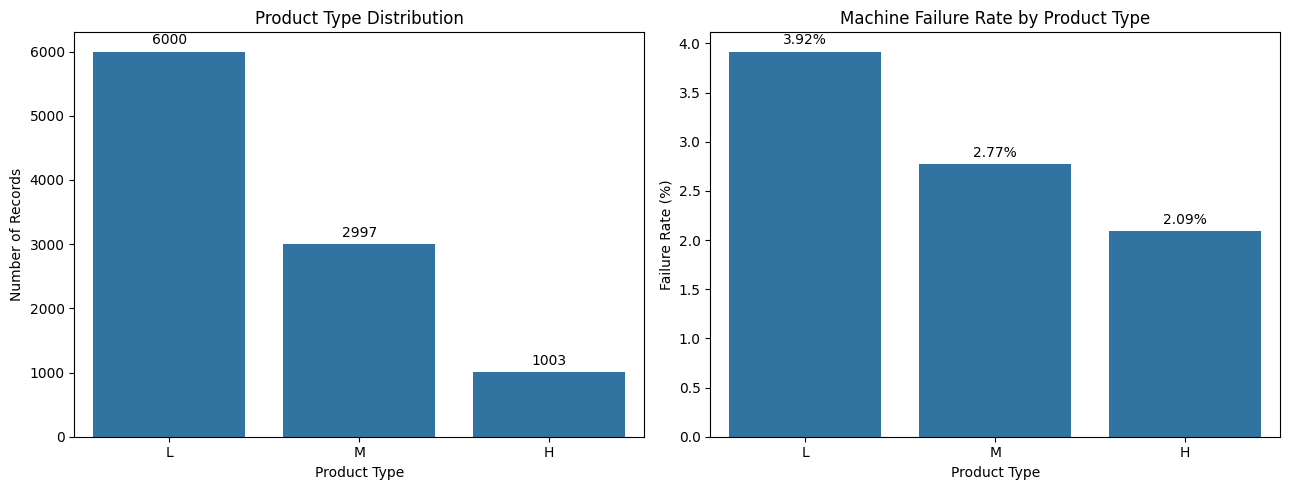

In [13]:
# Categorical feature analysis

# Purpose: Analyze product type distribution and machine failure rates.

type_summary = df.groupby("Type").agg(
    Records=("Machine failure", "count"),
    Failures=("Machine failure", "sum"),
    Failure_Rate=("Machine failure", "mean")
).reset_index()

type_summary["Failure_Rate"] *= 100

display(type_summary.round(2))

# Visualize product type distribution and failure rates
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Product type counts
ax1 = sns.countplot(data=df, x="Type", order=["L", "M", "H"], ax=axes[0])

for container in ax1.containers:
    ax1.bar_label(container, fmt="%.0f", padding=3)

ax1.set_title("Product Type Distribution")
ax1.set_xlabel("Product Type")
ax1.set_ylabel("Number of Records")

# Failure rate by product type
ax2 = sns.barplot(
    data=type_summary,
    x="Type",
    y="Failure_Rate",
    order=["L", "M", "H"],
    ax=axes[1]
)

for container in ax2.containers:
    ax2.bar_label(container, fmt="%.2f%%", padding=3)

ax2.set_title("Machine Failure Rate by Product Type")
ax2.set_xlabel("Product Type")
ax2.set_ylabel("Failure Rate (%)")

plt.tight_layout()
plt.show()

## Categorical Feature Analysis

The product quality category (`Type`) was analyzed to understand its distribution and relationship with machine failures.

The dataset contains three categories:
- L – Low Quality
- M – Medium Quality
- H – High Quality

**Key Findings:**

- **Type L:** 6,000 records, 235 failures, 3.92% failure rate.
- **Type M:** 2,997 records, 83 failures, 2.77% failure rate.
- **Type H:** 1,003 records, 21 failures, 2.09% failure rate.

**Interpretation:**

Type L has the highest observed failure rate, whereas Type H has the lowest.

These findings indicate an association between product category and machine failure, but do not establish a causal relationship.

The `Type` feature will be retained for model development and appropriately encoded during preprocessing.

,No Failure,Failure
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


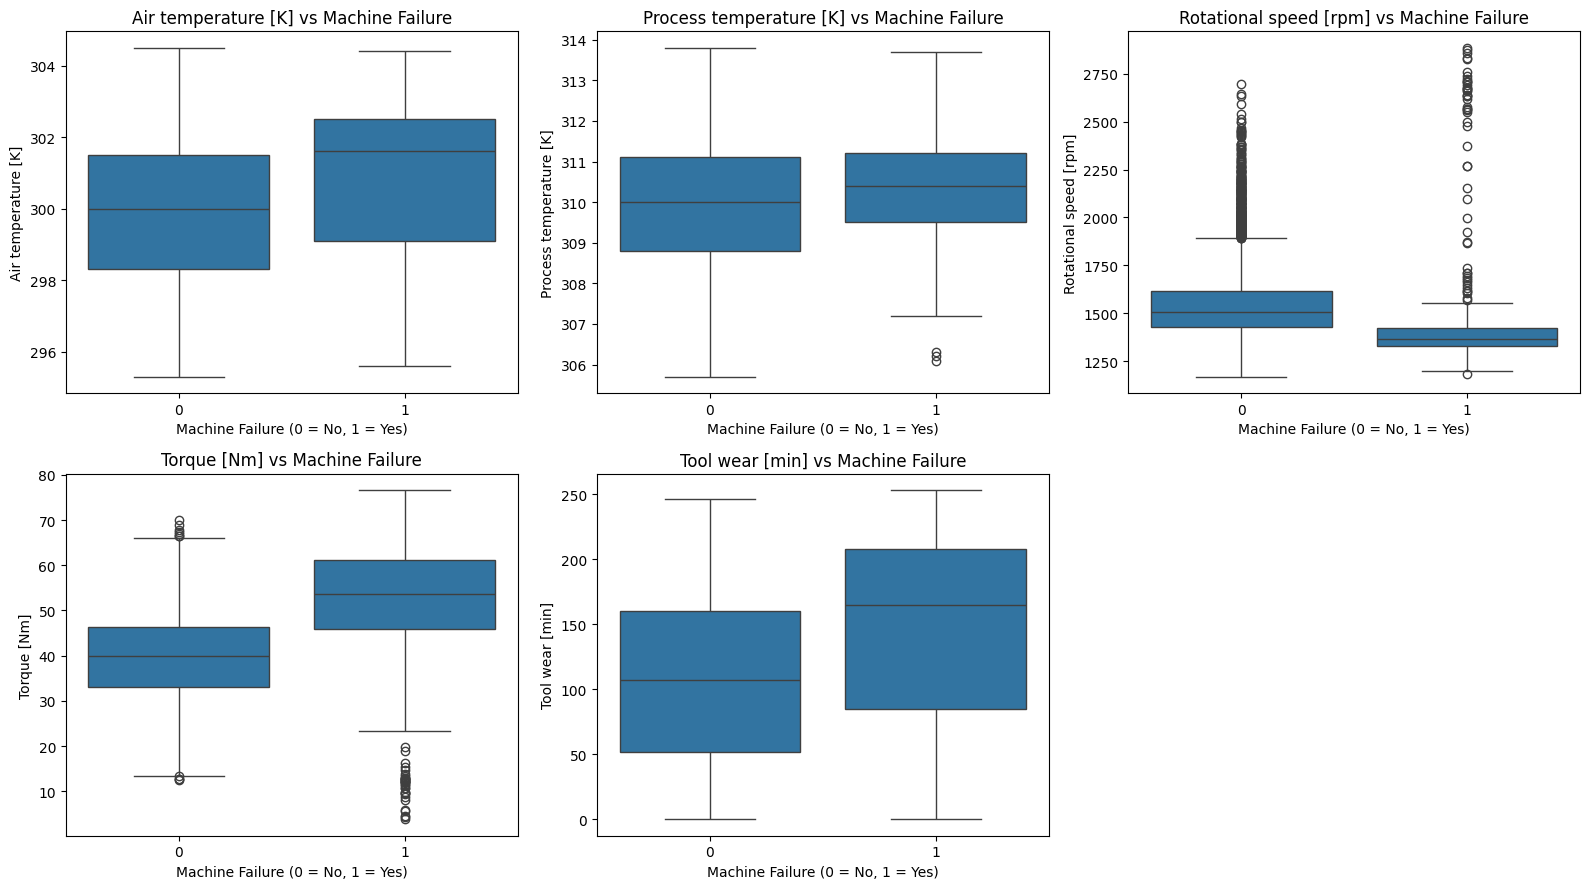

In [14]:
# Operating parameters vs machine failure

# Purpose: Compare operating parameters across machine failure classes.

failure_comparison = df.groupby("Machine failure")[numerical_features].mean().T

failure_comparison.columns = ["No Failure", "Failure"]

display(failure_comparison.round(2))

# Visualize operating parameters against machine failure
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(numerical_features):

    ax = sns.boxplot(
        data=df,
        x="Machine failure",
        y=column,
        ax=axes[i]
    )

    ax.set_title(f"{column} vs Machine Failure")
    ax.set_xlabel("Machine Failure (0 = No, 1 = Yes)")
    ax.set_ylabel(column)

plt.delaxes(axes[5])

plt.tight_layout()
plt.show()

## Operating Parameters vs Machine Failure

The numerical operating parameters were compared across machines with and without failures using descriptive statistics and boxplots.

**Key Findings:**

- **Air Temperature:** Slightly higher average temperature in failed machines (300.89 K).
- **Process Temperature:** Only a small difference between the two groups.
- **Rotational Speed:** Failed machines show a lower average speed (1496.49 rpm).
- **Torque:** Failed machines show higher average torque (50.17 Nm).
- **Tool Wear:** Failed machines have higher average tool wear (143.78 minutes).

**Interpretation:**

Torque and Tool Wear show noticeable increases in failed machines, while Rotational Speed shows a decrease. Temperature measurements show comparatively smaller differences.

**Conclusion:**

Torque, Tool Wear, and Rotational Speed appear to be important operating parameters for further investigation in machine failure prediction.

These observations indicate associations, not direct causation. All five numerical features will be retained for model development.

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.00,0.88,0.02,-0.01,0.01,0.08
Process temperature [K],0.88,1.00,0.02,-0.01,0.01,0.04
Rotational speed [rpm],0.02,0.02,1.00,-0.88,0.00,-0.04
Torque [Nm],-0.01,-0.01,-0.88,1.00,-0.00,0.19
Tool wear [min],0.01,0.01,0.00,-0.00,1.00,0.11
Machine failure,0.08,0.04,-0.04,0.19,0.11,1.00


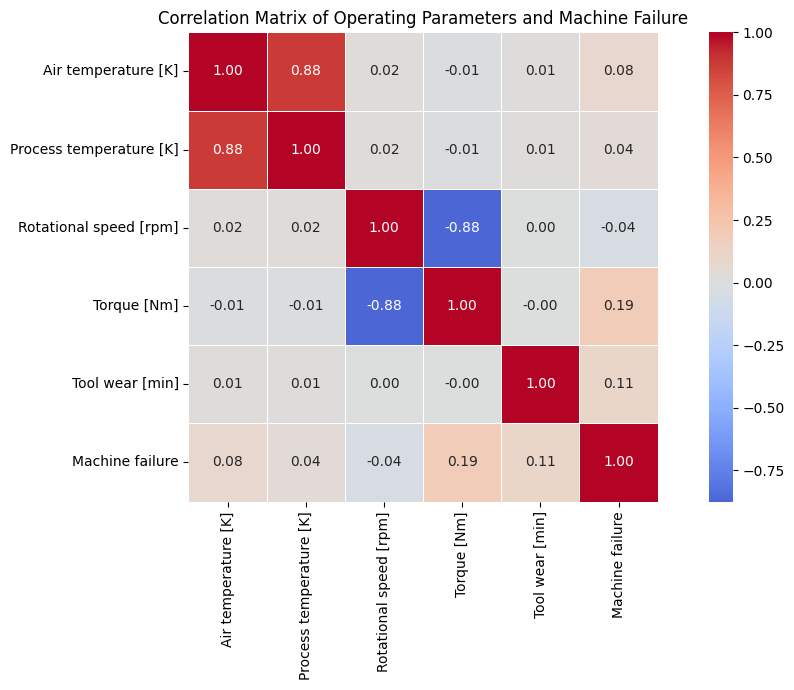

In [15]:
# Correlation Analysis

# Purpose: Analyze correlations between numerical features and machine failure.

correlation_features = numerical_features + ["Machine failure"]

correlation_matrix = df[correlation_features].corr(method="pearson")

# Display correlation values
display(correlation_matrix.round(2))

# Visualize the correlation matrix
plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Matrix of Operating Parameters and Machine Failure")
plt.tight_layout()
plt.show()

## Correlation Analysis

Pearson correlation was used to examine linear relationships between numerical operating parameters and machine failure.

**Key Findings:**

- Torque has the highest positive correlation with machine failure (0.19).
- Tool Wear shows a positive correlation of 0.11.
- Air Temperature and Process Temperature show weak positive correlations.
- Rotational Speed has a weak negative correlation (-0.04).

**Feature Relationships:**

- Air Temperature and Process Temperature show a strong positive correlation (0.88).
- Rotational Speed and Torque show a strong negative correlation (-0.88).

**Interpretation:**

Although individual features show relatively weak linear correlations with machine failure, they may still contribute to prediction through nonlinear relationships and feature interactions.

The strong correlations between certain input features will also be considered during model development, particularly when evaluating multicollinearity.

**Conclusion:**

All five numerical operating parameters will be retained for further analysis. Feature importance and predictive contribution will be evaluated using the developed models rather than relying solely on correlation values.

In [16]:
# Feature selection and data leakage audit

# Purpose: Identify valid input features and prevent data leakage.

# Identifier columns
identifier_columns = ["UDI", "Product ID"]

# Target variable
target_column = "Machine failure"

# Failure-mode columns that must be excluded
leakage_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Valid input features
feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Verify that all expected columns exist
expected_columns = (
    identifier_columns + feature_columns +
    [target_column] + leakage_columns
)

assert set(expected_columns) == set(df.columns), "Unexpected dataset columns detected."

# Create feature and target datasets
X = df[feature_columns].copy()
y = df[target_column].copy()

# Display feature selection summary
feature_audit = pd.DataFrame({
    "Column": expected_columns,
    "Role": (
        ["Identifier"] * len(identifier_columns) +
        ["Input Feature"] * len(feature_columns) +
        ["Target"] +
        ["Excluded - Data Leakage"] * len(leakage_columns)
    )
})

display(feature_audit)

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Leakage Columns Included:",
      any(column in X.columns for column in leakage_columns))

,Column,Role
0,UDI,Identifier
1,Product ID,Identifier
2,Type,Input Feature
3,Air temperature [K],Input Feature
4,Process temperature [K],Input Feature
5,Rotational speed [rpm],Input Feature
6,Torque [Nm],Input Feature
7,Tool wear [min],Input Feature
8,Machine failure,Target
9,TWF,Excluded - Data Leakage


Input Features Shape: (10000, 6)
Target Shape: (10000,)
Leakage Columns Included: False


## Feature Selection and Validation

The feature selection audit confirms that six valid input features and one target variable have been selected.

Identifier columns (`UDI`, `Product ID`) and five failure-mode indicators (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) have been excluded.

The leakage validation confirms that none of the excluded failure-mode columns are present in the input features.

**Conclusion:** The selected dataset is ready for train-test splitting and subsequent preprocessing.

In [17]:
# Train-Test Split

# Purpose: Split the dataset while preserving machine failure class proportions.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verify dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# Compare class distributions
split_summary = pd.DataFrame({
    "Training Count": y_train.value_counts().sort_index(),
    "Training (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Testing Count": y_test.value_counts().sort_index(),
    "Testing (%)": y_test.value_counts(normalize=True).sort_index() * 100
})

display(split_summary.round(2))

Training Features: (8000, 6)
Testing Features: (2000, 6)

Training Target: (8000,)
Testing Target: (2000,)


,Training Count,Training (%),Testing Count,Testing (%)
Machine failure,,,,
0,7729,96.61,1932,96.6
1,271,3.39,68,3.4


## Train-Test Split

The dataset was divided into training (80%) and testing (20%) sets using stratified sampling.

Stratification was applied to preserve the original machine failure distribution across both datasets.

**Results:**
- Training records: 8,000
- Testing records: 2,000
- Training failure cases: 271
- Testing failure cases: 68

**Conclusion:**

The class distribution is consistently maintained across both sets. The test dataset will remain untouched during model training, preprocessing decisions, and hyperparameter tuning to ensure an unbiased final evaluation.

In [18]:
# Create a validation set

# Purpose: Create a validation set for model selection and tuning.

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Verify dataset dimensions
print("Training Features:", X_train.shape)
print("Validation Features:", X_val.shape)
print("Testing Features:", X_test.shape)

# Compare class distributions
validation_summary = pd.DataFrame({
    "Training": y_train.value_counts().sort_index(),
    "Validation": y_val.value_counts().sort_index(),
    "Testing": y_test.value_counts().sort_index()
})

display(validation_summary)

Training Features: (6400, 6)
Validation Features: (1600, 6)
Testing Features: (2000, 6)


,Training,Validation,Testing
Machine failure,,,
0,6183,1546,1932
1,217,54,68


## Training, Validation and Testing Split

The original dataset was divided into three subsets using stratified sampling:

- Training: 64% (6,400 records)
- Validation: 16% (1,600 records)
- Testing: 20% (2,000 records)

**Purpose of Each Dataset:**

- Training data: Model fitting and learning.
- Validation data: Model selection, hyperparameter tuning and threshold evaluation.
- Testing data: Final unbiased model evaluation.

The failure-class distribution is maintained across all three subsets.

**Conclusion:** The data is ready for preprocessing and model development. The test dataset will remain untouched until final evaluation.

In [19]:
# Feature preprocessing

# Purpose: Scale numerical features and encode categorical features.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate numerical and categorical columns
numerical_columns = numerical_features
categorical_columns = ["Type"]

# Define preprocessing transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_columns)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and testing data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Get transformed feature names
processed_feature_names = preprocessor.get_feature_names_out()

# Display transformed datasets
print("Training Shape:", X_train_processed.shape)
print("Validation Shape:", X_val_processed.shape)
print("Testing Shape:", X_test_processed.shape)

print("\nTransformed Features:")
print(processed_feature_names)

Training Shape: (6400, 8)
Validation Shape: (1600, 8)
Testing Shape: (2000, 8)

Transformed Features:
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


## Feature Preprocessing

Applied StandardScaler to the five numerical features and One-Hot Encoding to the categorical feature `Type`.

The categorical feature was converted into three binary columns: `Type_H`, `Type_L`, and `Type_M`.

The preprocessing pipeline was fitted exclusively on the training dataset and applied to the validation and testing datasets to prevent data leakage.

Final feature dimensions:
- Training: 6,400 × 8
- Validation: 1,600 × 8
- Testing: 2,000 × 8

The final dataset contains eight model-ready features, with all identified outliers retained to preserve potentially meaningful failure-related information.

## Outlier Treatment Decision

The IQR method identified potential outliers in Rotational Speed and Torque.

Further investigation revealed higher machine failure rates among these observations, particularly for lower and upper Torque outliers.

Since these extreme values may represent meaningful machine operating conditions rather than data errors, they will be retained without removal or capping.

StandardScaler will be applied to numerical features during preprocessing. However, scaling does not eliminate the influence of extreme observations.

**Conclusion:** All identified outliers are retained to preserve potentially valuable failure-related information. Their influence will be considered during model evaluation.

# Phase 2 — ML and ANN Development

## Build the Logistic Regression baseline model

In [20]:
# Purpose: Train a Logistic Regression baseline classifier.

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [21]:
# Validation predictions

# Purpose: Generate predictions and probabilities on validation data.

y_val_pred = logistic_model.predict(X_val_processed)

y_val_prob = logistic_model.predict_proba(X_val_processed)[:, 1]

print("Validation predictions generated successfully!")
print("Predictions Shape:", y_val_pred.shape)
print("Probability Shape:", y_val_prob.shape)

Validation predictions generated successfully!
Predictions Shape: (1600,)
Probability Shape: (1600,)


In [22]:
# Purpose: Evaluate Logistic Regression using validation metrics.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("LOGISTIC REGRESSION - VALIDATION RESULTS")

print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_val, y_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, y_val_prob), 4))

cm = confusion_matrix(y_val, y_val_pred)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

LOGISTIC REGRESSION - VALIDATION RESULTS
Accuracy: 0.8231
Precision: 0.1433
Recall: 0.8519
F1-Score: 0.2453
ROC-AUC: 0.8927
PR-AUC: 0.4197

Confusion Matrix:
[[1271  275]
 [   8   46]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.82      0.90      1546
     Failure       0.14      0.85      0.25        54

    accuracy                           0.82      1600
   macro avg       0.57      0.84      0.57      1600
weighted avg       0.97      0.82      0.88      1600



## Logistic Regression — Validation Evaluation

The Logistic Regression model was evaluated on 1,600 validation records using a default classification threshold of 0.5.

**Evaluation Results:**
- Accuracy: 82.31%
- Precision: 14.33%
- Recall: 85.19%
- F1-Score: 24.53%
- ROC-AUC: 0.8927
- PR-AUC: 0.4197

**Confusion Matrix Analysis:**
- True Negatives: 1,271
- False Positives: 275
- False Negatives: 8
- True Positives: 46

**Business Interpretation:**

The model successfully identified 46 of 54 actual machine failures, achieving high recall of 85.19%. However, its low precision indicates that many failure alerts are false positives, potentially resulting in unnecessary maintenance inspections.

**Conclusion:**

Logistic Regression provides a useful baseline for detecting machine failures. Further model comparison and threshold optimization are required to improve precision while maintaining high recall.

In [23]:
# Random Forest model

# Purpose: Train a Random Forest classifier for model comparison.

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [24]:
# Purpose: Generate Random Forest predictions on validation data.

y_rf_val_pred = rf_model.predict(X_val_processed)

y_rf_val_prob = rf_model.predict_proba(X_val_processed)[:, 1]

print("Random Forest validation predictions generated!")
print("Predictions Shape:", y_rf_val_pred.shape)
print("Probability Shape:", y_rf_val_prob.shape)

Random Forest validation predictions generated!
Predictions Shape: (1600,)
Probability Shape: (1600,)


In [25]:
# Purpose: Evaluate Random Forest using validation metrics.

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

print("RANDOM FOREST - VALIDATION RESULTS")

print("Accuracy:", round(accuracy_score(y_val, y_rf_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_rf_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_rf_val_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_val, y_rf_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_rf_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, y_rf_val_prob), 4))

cm_rf = confusion_matrix(y_val, y_rf_val_pred)

print("\nConfusion Matrix:")
print(cm_rf)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_rf_val_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

RANDOM FOREST - VALIDATION RESULTS
Accuracy: 0.9788
Precision: 0.8846
Recall: 0.4259
F1-Score: 0.575
ROC-AUC: 0.964
PR-AUC: 0.7347

Confusion Matrix:
[[1543    3]
 [  31   23]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1546
     Failure       0.88      0.43      0.57        54

    accuracy                           0.98      1600
   macro avg       0.93      0.71      0.78      1600
weighted avg       0.98      0.98      0.98      1600



## Random Forest — Validation Evaluation

The Random Forest model was evaluated on 1,600 validation records using the default classification threshold of 0.5.

**Evaluation Results:**
- Accuracy: 97.88%
- Precision: 88.46%
- Recall: 42.59%
- F1-Score: 57.50%
- ROC-AUC: 0.9640
- PR-AUC: 0.7347

**Confusion Matrix Analysis:**
- True Negatives: 1,543
- False Positives: 3
- False Negatives: 31
- True Positives: 23

**Business Interpretation:**

Random Forest achieves high precision and generates very few false alarms. However, it detects only 23 of the 54 actual failures, missing 31 failures.

Although its ROC-AUC and PR-AUC indicate strong ranking performance, its default classification threshold does not provide sufficient failure detection for a recall-focused maintenance strategy.

**Conclusion:**

Random Forest demonstrates stronger overall discrimination and precision than Logistic Regression. However, its low failure recall requires further investigation through decision-threshold optimization.

In [28]:
# Decision Tree Classifier

# Purpose: Train a Decision Tree classifier for machine failure prediction.

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(X_train_processed, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [29]:
# Purpose: Generate Decision Tree predictions on validation data.

y_dt_val_pred = dt_model.predict(X_val_processed)

y_dt_val_prob = dt_model.predict_proba(X_val_processed)[:, 1]

print("Decision Tree validation predictions generated!")
print("Predictions Shape:", y_dt_val_pred.shape)
print("Probability Shape:", y_dt_val_prob.shape)

Decision Tree validation predictions generated!
Predictions Shape: (1600,)
Probability Shape: (1600,)


In [30]:
# Purpose: Evaluate Decision Tree using validation metrics.

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

print("DECISION TREE - VALIDATION RESULTS")

print("Accuracy:", round(accuracy_score(y_val, y_dt_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_dt_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_dt_val_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_val, y_dt_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_dt_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, y_dt_val_prob), 4))

cm_dt = confusion_matrix(y_val, y_dt_val_pred)

print("\nConfusion Matrix:")
print(cm_dt)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_dt_val_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

DECISION TREE - VALIDATION RESULTS
Accuracy: 0.9225
Precision: 0.2892
Recall: 0.8889
F1-Score: 0.4364
ROC-AUC: 0.9084
PR-AUC: 0.4655

Confusion Matrix:
[[1428  118]
 [   6   48]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       1.00      0.92      0.96      1546
     Failure       0.29      0.89      0.44        54

    accuracy                           0.92      1600
   macro avg       0.64      0.91      0.70      1600
weighted avg       0.97      0.92      0.94      1600



## Decision Tree — Validation Evaluation

The Decision Tree classifier was evaluated on 1,600 validation records using a default classification threshold of 0.5.

**Evaluation Results:**
- Accuracy: 92.25%
- Precision: 28.92%
- Recall: 88.89%
- F1-Score: 43.64%
- ROC-AUC: 0.9084
- PR-AUC: 0.4655

**Confusion Matrix Analysis:**
- True Negatives: 1,428
- False Positives: 118
- False Negatives: 6
- True Positives: 48

**Business Interpretation:**

The Decision Tree successfully detected 48 out of 54 actual machine failures, achieving 88.89% recall. It missed only six failures, making it promising for a recall-focused predictive maintenance application.

However, its precision of 28.92% indicates that false failure alerts remain relatively high.

**Conclusion:**

Decision Tree provides stronger failure detection than the previous baseline models at the default threshold. Its recall is the highest so far, although its precision and overall discrimination require further improvement.

In [31]:
# Gradient Boosting

# Purpose: Train a Gradient Boosting classifier for machine failure prediction.

from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_processed, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [32]:
# Purpose: Generate Gradient Boosting predictions on validation data.

y_gb_val_pred = gb_model.predict(X_val_processed)

y_gb_val_prob = gb_model.predict_proba(X_val_processed)[:, 1]

print("Gradient Boosting validation predictions generated!")
print("Predictions Shape:", y_gb_val_pred.shape)
print("Probability Shape:", y_gb_val_prob.shape)

Gradient Boosting validation predictions generated!
Predictions Shape: (1600,)
Probability Shape: (1600,)


In [33]:
# Purpose: Evaluate Gradient Boosting using validation metrics.

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

print("GRADIENT BOOSTING - VALIDATION RESULTS")

print("Accuracy:", round(accuracy_score(y_val, y_gb_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_gb_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_gb_val_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_val, y_gb_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_gb_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, y_gb_val_prob), 4))

cm_gb = confusion_matrix(y_val, y_gb_val_pred)

print("\nConfusion Matrix:")
print(cm_gb)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_gb_val_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

GRADIENT BOOSTING - VALIDATION RESULTS
Accuracy: 0.9831
Precision: 0.8293
Recall: 0.6296
F1-Score: 0.7158
ROC-AUC: 0.9773
PR-AUC: 0.7668

Confusion Matrix:
[[1539    7]
 [  20   34]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1546
     Failure       0.83      0.63      0.72        54

    accuracy                           0.98      1600
   macro avg       0.91      0.81      0.85      1600
weighted avg       0.98      0.98      0.98      1600



## Gradient Boosting — Validation Evaluation

The Gradient Boosting classifier was evaluated on 1,600 validation records using a default classification threshold of 0.5.

**Evaluation Results:**
- Accuracy: 98.31%
- Precision: 82.93%
- Recall: 62.96%
- F1-Score: 71.58%
- ROC-AUC: 0.9773
- PR-AUC: 0.7668

**Confusion Matrix Analysis:**
- True Negatives: 1,539
- False Positives: 7
- False Negatives: 20
- True Positives: 34

**Business Interpretation:**

Gradient Boosting correctly identified 34 out of 54 actual machine failures while generating only seven false alarms. Its high precision indicates that most predicted failure alerts are correct.

However, it missed 20 actual failures, indicating that its recall needs improvement for a maintenance strategy focused on preventing unexpected breakdowns.

**Conclusion:**

Gradient Boosting currently provides the strongest overall validation performance among the four evaluated models, achieving the highest F1-score, ROC-AUC, and PR-AUC. Its probability-based predictions will be further investigated through decision-threshold optimization.

In [34]:
# Support Vector Machine (SVM)

# Purpose: Train an SVM classifier for machine failure prediction.

from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_processed, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [35]:
# Purpose: Generate SVM predictions on validation data.

y_svm_val_pred = svm_model.predict(X_val_processed)

y_svm_val_prob = svm_model.predict_proba(X_val_processed)[:, 1]

print("SVM validation predictions generated!")
print("Predictions Shape:", y_svm_val_pred.shape)
print("Probability Shape:", y_svm_val_prob.shape)

SVM validation predictions generated!
Predictions Shape: (1600,)
Probability Shape: (1600,)


In [36]:
# Evaluate SVM

# Purpose: Evaluate SVM using validation metrics.

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

print("SVM - VALIDATION RESULTS")

print("Accuracy:", round(accuracy_score(y_val, y_svm_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_svm_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_svm_val_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_val, y_svm_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_svm_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, y_svm_val_prob), 4))

cm_svm = confusion_matrix(y_val, y_svm_val_pred)

print("\nConfusion Matrix:")
print(cm_svm)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_svm_val_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

SVM - VALIDATION RESULTS
Accuracy: 0.9163
Precision: 0.2727
Recall: 0.8889
F1-Score: 0.4174
ROC-AUC: 0.9594
PR-AUC: 0.6308

Confusion Matrix:
[[1418  128]
 [   6   48]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       1.00      0.92      0.95      1546
     Failure       0.27      0.89      0.42        54

    accuracy                           0.92      1600
   macro avg       0.63      0.90      0.69      1600
weighted avg       0.97      0.92      0.94      1600



## Support Vector Machine — Validation Evaluation

The SVM classifier with an RBF kernel was evaluated on 1,600 validation records using a default classification threshold of 0.5.

**Evaluation Results:**
- Accuracy: 91.63%
- Precision: 27.27%
- Recall: 88.89%
- F1-Score: 41.74%
- ROC-AUC: 0.9594
- PR-AUC: 0.6308

**Confusion Matrix Analysis:**
- True Negatives: 1,418
- False Positives: 128
- False Negatives: 6
- True Positives: 48

**Business Interpretation:**

SVM successfully detected 48 out of 54 actual machine failures, achieving 88.89% recall. However, it generated 128 false alarms, resulting in relatively low precision.

**Conclusion:**

SVM demonstrates strong failure detection and good ranking performance. Its high recall makes it a potential candidate for predictive maintenance, although its false-positive rate requires further attention.

In [37]:
# Threshold analysis — Multiple models

# Purpose: Compare classification thresholds across all five ML models.

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

model_probabilities = {
    "Logistic Regression": y_val_prob,
    "Random Forest": y_rf_val_prob,
    "Decision Tree": y_dt_val_prob,
    "Gradient Boosting": y_gb_val_prob,
    "SVM": y_svm_val_prob
}

threshold_results = []

thresholds = np.arange(0.10, 0.91, 0.05)

for model_name, probabilities in model_probabilities.items():

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(y_val, predictions, zero_division=0),
            "Recall": recall_score(y_val, predictions, zero_division=0),
            "F1-Score": f1_score(y_val, predictions, zero_division=0)
        })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Model,Threshold,Precision,Recall,F1-Score
0,Logistic Regression,0.10,0.0491,0.9444,0.0933
1,Logistic Regression,0.15,0.0584,0.9444,0.1099
2,Logistic Regression,0.20,0.0664,0.9259,0.1239
3,Logistic Regression,0.25,0.0757,0.9074,0.1398
4,Logistic Regression,0.30,0.0886,0.9074,0.1614
...,...,...,...,...,...
80,SVM,0.70,0.7895,0.2778,0.4110
81,SVM,0.75,0.8333,0.2778,0.4167
82,SVM,0.80,0.9231,0.2222,0.3582
83,SVM,0.85,0.9091,0.1852,0.3077


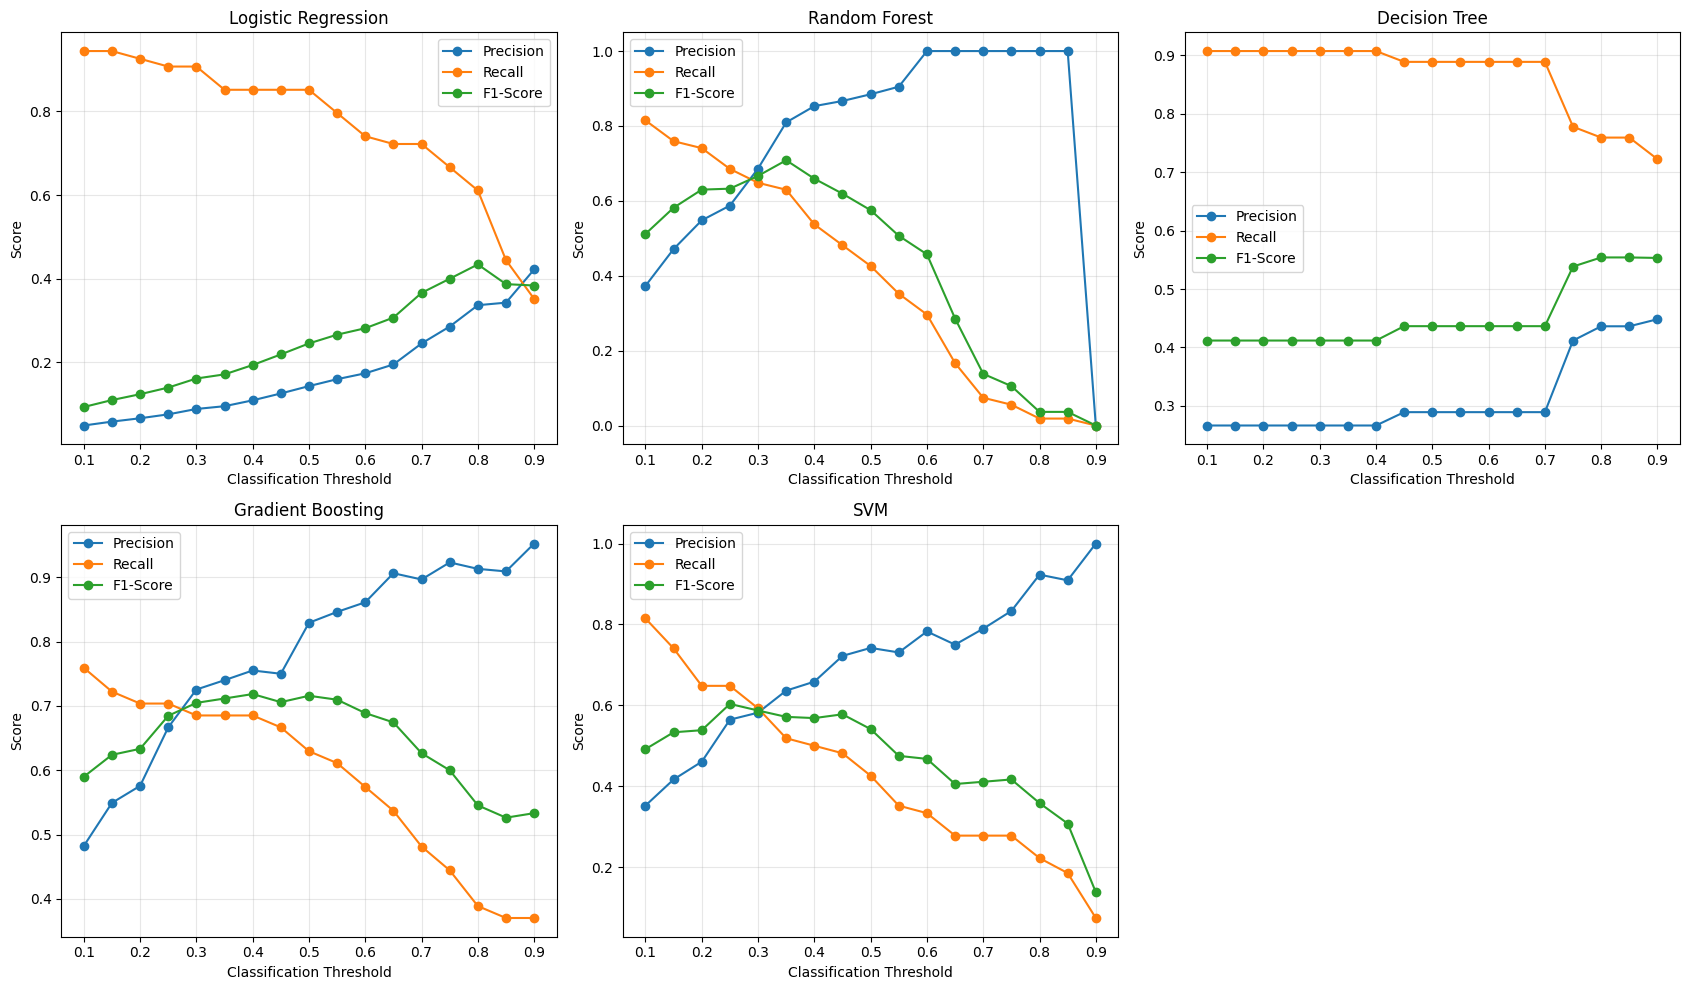

In [38]:
# Purpose: Visualize precision and recall across classification thresholds.

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for index, model_name in enumerate(model_probabilities):

    model_data = threshold_df[
        threshold_df["Model"] == model_name
    ]

    axes[index].plot(
        model_data["Threshold"],
        model_data["Precision"],
        marker="o",
        label="Precision"
    )

    axes[index].plot(
        model_data["Threshold"],
        model_data["Recall"],
        marker="o",
        label="Recall"
    )

    axes[index].plot(
        model_data["Threshold"],
        model_data["F1-Score"],
        marker="o",
        label="F1-Score"
    )

    axes[index].set_title(model_name)
    axes[index].set_xlabel("Classification Threshold")
    axes[index].set_ylabel("Score")
    axes[index].legend()
    axes[index].grid(alpha=0.3)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

## Classical Machine Learning — Comparative Evaluation

Five classical machine learning algorithms were evaluated using the same validation dataset. Decision thresholds were optimized independently using validation F1-scores.

**Key Findings:**

- Gradient Boosting achieved the highest F1-score of 71.84%, providing the best precision-recall balance.
- Random Forest achieved the highest precision of 80.95% and the lowest false-positive count of 8.
- Decision Tree achieved the highest recall of 75.93% after threshold optimization.
- SVM demonstrated moderate precision and recall.
- Logistic Regression provided the baseline for comparison but showed the weakest F1-score.

**Business Interpretation:**

The results demonstrate different trade-offs between missed machine failures and unnecessary maintenance alerts. Gradient Boosting provides the strongest overall balance, Random Forest reduces false alarms, and Decision Tree prioritizes failure detection.

**Conclusion:**

Gradient Boosting, Random Forest, and Decision Tree are shortlisted for further investigation. ANN will now be developed to evaluate whether a neural network can provide additional predictive value over the classical machine learning approaches.

In [39]:
# Purpose: Identify the threshold with the highest validation F1-score.

best_threshold_results = (
    threshold_df.loc[
        threshold_df.groupby("Model")["F1-Score"].idxmax()
    ]
    .sort_values("F1-Score", ascending=False)
    .reset_index(drop=True)
)

display(best_threshold_results.round(4))

,Model,Threshold,Precision,Recall,F1-Score
0,Gradient Boosting,0.40,0.7551,0.6852,0.7184
1,Random Forest,0.35,0.8095,0.6296,0.7083
2,SVM,0.25,0.5645,0.6481,0.6034
3,Decision Tree,0.80,0.4362,0.7593,0.5541
4,Logistic Regression,0.80,0.3367,0.6111,0.4342


In [40]:
# Purpose: Evaluate all five models using their optimized validation thresholds.

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

optimized_results = []

for _, row in best_threshold_results.iterrows():

    model_name = row["Model"]
    threshold = row["Threshold"]

    probabilities = model_probabilities[model_name]
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    optimized_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-Score": f1_score(y_val, predictions, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

optimized_comparison = pd.DataFrame(optimized_results)

display(optimized_comparison.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,TN,FP,FN,TP
0,Gradient Boosting,0.40,0.9819,0.7551,0.6852,0.7184,1534,12,17,37
1,Random Forest,0.35,0.9825,0.8095,0.6296,0.7083,1538,8,20,34
2,SVM,0.25,0.9712,0.5645,0.6481,0.6034,1519,27,19,35
3,Decision Tree,0.80,0.9588,0.4362,0.7593,0.5541,1493,53,13,41
4,Logistic Regression,0.80,0.9462,0.3367,0.6111,0.4342,1481,65,21,33


## Classical Machine Learning — Comparative Evaluation

Five classical machine learning algorithms were evaluated using the same validation dataset. Decision thresholds were optimized independently using validation F1-scores.

**Key Findings:**

- Gradient Boosting achieved the highest F1-score of 71.84%, providing the best precision-recall balance.
- Random Forest achieved the highest precision of 80.95% and the lowest false-positive count of 8.
- Decision Tree achieved the highest recall of 75.93% after threshold optimization.
- SVM demonstrated moderate precision and recall.
- Logistic Regression provided the baseline for comparison but showed the weakest F1-score.

**Business Interpretation:**

The results demonstrate different trade-offs between missed machine failures and unnecessary maintenance alerts. Gradient Boosting provides the strongest overall balance, Random Forest reduces false alarms, and Decision Tree prioritizes failure detection.

**Conclusion:**

Gradient Boosting, Random Forest, and Decision Tree are shortlisted for further investigation. ANN will now be developed to evaluate whether a neural network can provide additional predictive value over the classical machine learning approaches.

---------------------------------------------------------------------------------------

In [26]:
# ANN model architecture

# Purpose: Build an Artificial Neural Network for machine failure classification.

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(42)

ann_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

ann_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

## ANN Architecture Design

A feedforward Artificial Neural Network was developed for binary machine failure classification.

**Architecture:**
- Input layer: 8 features
- Hidden layer 1: 64 neurons with ReLU activation
- Hidden layer 2: 32 neurons with ReLU activation
- Output layer: 1 neuron with Sigmoid activation

**Training Configuration:**
- Optimizer: Adam
- Learning Rate: 0.001
- Loss Function: Binary Crossentropy
- Random Seed: 42

**Model Parameters:**
- Total Parameters: 2,689
- Trainable Parameters: 2,689
- Non-trainable Parameters: 0

The sigmoid output estimates the probability of machine failure, allowing the model to classify observations into failure and no-failure categories using a decision threshold.

In [27]:
# Train the ANN

# Purpose: Train ANN while accounting for class imbalance.

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, class_weights))

print("Class Weights:", class_weight_dict)

history = ann_model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weight_dict,
    verbose=1
)

Class Weights: {np.int64(0): np.float64(0.5175481158013909), np.int64(1): np.float64(14.746543778801843)}
Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7794 - loss: 0.5286 - val_accuracy: 0.8281 - val_loss: 0.4305
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8422 - loss: 0.3718 - val_accuracy: 0.8650 - val_loss: 0.3625
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8536 - loss: 0.3335 - val_accuracy: 0.8662 - val_loss: 0.3478
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8661 - loss: 0.3117 - val_accuracy: 0.8675 - val_loss: 0.3353
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8708 - loss: 0.2932 - val_accuracy: 0.8687 - val_loss: 0.3219
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8781 - loss: 0.2765 - val_accuracy: 0.8731 - val_loss: 0.3072
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8844 - loss: 0.2618 - val_accuracy: 0.8756 - val_loss: 0.294

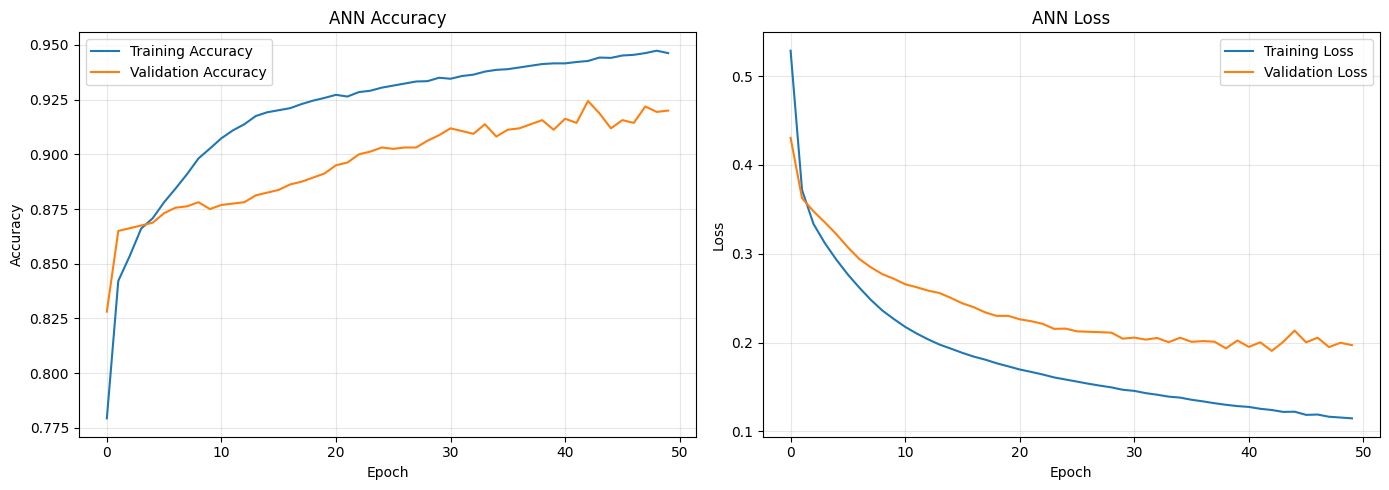

In [41]:
# Purpose: Visualize ANN training and validation performance across epochs.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("ANN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("ANN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
# Purpose: Generate ANN predictions and failure probabilities on validation data.

y_ann_val_prob = ann_model.predict(
    X_val_processed
).ravel()

y_ann_val_pred = (y_ann_val_prob >= 0.5).astype(int)

print("ANN validation predictions generated!")
print("Predictions Shape:", y_ann_val_pred.shape)
print("Probability Shape:", y_ann_val_prob.shape)

50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
ANN validation predictions generated!
Predictions Shape: (1600,)
Probability Shape: (1600,)


## ANN Training Performance Analysis

The ANN was trained for 50 epochs using class weights to address the imbalance in machine failure observations.

**Training Observations:**
- Training accuracy increased to 94.63%.
- Validation accuracy reached a maximum of 92.44% at epoch 43.
- Training loss decreased to 0.1146.
- Minimum validation loss was 0.1905 at epoch 43.

**Learning Curve Analysis:**

Both training and validation accuracy generally improved, while their corresponding losses decreased throughout training.

The validation loss showed minor fluctuations during later epochs, indicating a possible generalization gap. However, there was no severe divergence between training and validation performance.

**Conclusion:**

The ANN successfully learned patterns from the training data and demonstrated improving validation performance. Epoch 43 recorded the lowest validation loss, suggesting that early stopping could help avoid unnecessary training in future experiments.

In [43]:
# Purpose: Evaluate ANN using validation metrics.

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

print("ANN - VALIDATION RESULTS")

print("Accuracy:", round(accuracy_score(y_val, y_ann_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_ann_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_ann_val_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_val, y_ann_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_ann_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, y_ann_val_prob), 4))

cm_ann = confusion_matrix(y_val, y_ann_val_pred)

print("\nConfusion Matrix:")
print(cm_ann)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_ann_val_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

ANN - VALIDATION RESULTS
Accuracy: 0.92
Precision: 0.2771
Recall: 0.8519
F1-Score: 0.4182
ROC-AUC: 0.9565
PR-AUC: 0.691

Confusion Matrix:
[[1426  120]
 [   8   46]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.92      0.96      1546
     Failure       0.28      0.85      0.42        54

    accuracy                           0.92      1600
   macro avg       0.64      0.89      0.69      1600
weighted avg       0.97      0.92      0.94      1600



## ANN — Validation Evaluation

The Artificial Neural Network was evaluated on 1,600 validation records using a default classification threshold of 0.5.

**Evaluation Results:**
- Accuracy: 92.00%
- Precision: 27.71%
- Recall: 85.19%
- F1-Score: 41.82%
- ROC-AUC: 0.9565
- PR-AUC: 0.6910

**Confusion Matrix Analysis:**
- True Negatives: 1,426
- False Positives: 120
- False Negatives: 8
- True Positives: 46

**Business Interpretation:**

The ANN correctly identified 46 out of 54 actual machine failures, achieving 85.19% recall. However, it generated 120 false alarms, resulting in relatively low precision.

**Conclusion:**

ANN demonstrated strong failure detection and competitive probability-ranking performance. However, Gradient Boosting achieved better F1-score, ROC-AUC and PR-AUC on the same validation dataset. Further threshold optimization and controlled ANN experiments will be conducted to investigate potential improvements.

# Phase 3 — Model Evaluation and Reliability Audit

## 3.1 — Consolidated Model Performance Comparison

In [55]:

# Purpose: Compare the validation performance of all trained ML and ANN models.

model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.8231,
        "Precision": 0.1433,
        "Recall": 0.8519,
        "F1-Score": 0.2453,
        "ROC-AUC": 0.8927,
        "PR-AUC": 0.4197
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.9788,
        "Precision": 0.8846,
        "Recall": 0.4259,
        "F1-Score": 0.5750,
        "ROC-AUC": 0.9640,
        "PR-AUC": 0.7347
    },
    {
        "Model": "Decision Tree",
        "Accuracy": 0.9225,
        "Precision": 0.2892,
        "Recall": 0.8889,
        "F1-Score": 0.4364,
        "ROC-AUC": 0.9084,
        "PR-AUC": 0.4655
    },
    {
        "Model": "Gradient Boosting",
        "Accuracy": 0.9831,
        "Precision": 0.8293,
        "Recall": 0.6296,
        "F1-Score": 0.7158,
        "ROC-AUC": 0.9773,
        "PR-AUC": 0.7668
    },
    {
        "Model": "SVM",
        "Accuracy": 0.9163,
        "Precision": 0.2727,
        "Recall": 0.8889,
        "F1-Score": 0.4174,
        "ROC-AUC": 0.9594,
        "PR-AUC": 0.6308
    },
    {
        "Model": "ANN",
        "Accuracy": 0.9200,
        "Precision": 0.2771,
        "Recall": 0.8519,
        "F1-Score": 0.4182,
        "ROC-AUC": 0.9565,
        "PR-AUC": 0.6910
    }
])

display(
    model_comparison.sort_values(
        by="F1-Score",
        ascending=False
    ).reset_index(drop=True).round(4)
)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Gradient Boosting,0.9831,0.8293,0.6296,0.7158,0.9773,0.7668
1,Random Forest,0.9788,0.8846,0.4259,0.5750,0.9640,0.7347
2,Decision Tree,0.9225,0.2892,0.8889,0.4364,0.9084,0.4655
3,ANN,0.9200,0.2771,0.8519,0.4182,0.9565,0.6910
4,SVM,0.9163,0.2727,0.8889,0.4174,0.9594,0.6308
5,Logistic Regression,0.8231,0.1433,0.8519,0.2453,0.8927,0.4197


### Validation Performance Analysis

- **Gradient Boosting** achieved the highest F1-score (0.7158), ROC-AUC (0.9773), PR-AUC (0.7668), and accuracy (98.31%). It provides the strongest overall performance at the default threshold of 0.50.
- **Random Forest** achieved the highest precision (0.8846), indicating fewer false alarms, but its recall (0.4259) shows that it misses many actual machine failures.
- **Decision Tree** and **SVM** achieved the highest recall (0.8889), making them better at identifying failure cases at the cost of more false positives.
- **ANN** achieved a recall of 0.8519 and ROC-AUC of 0.9565, demonstrating good failure detection capability, although its precision (0.2771) was relatively low.
- **Logistic Regression** achieved the lowest F1-score (0.2453) and PR-AUC (0.4197), indicating weaker overall performance compared with the other models.

### Conclusion

Gradient Boosting is the strongest overall candidate based on the validation results at the default threshold. However, model selection should also consider the consequences of missed failures and unnecessary inspections. Therefore, we will investigate confusion matrices and decision thresholds before finalizing the model.

## 3.2 — Confusion Matrix Comparison

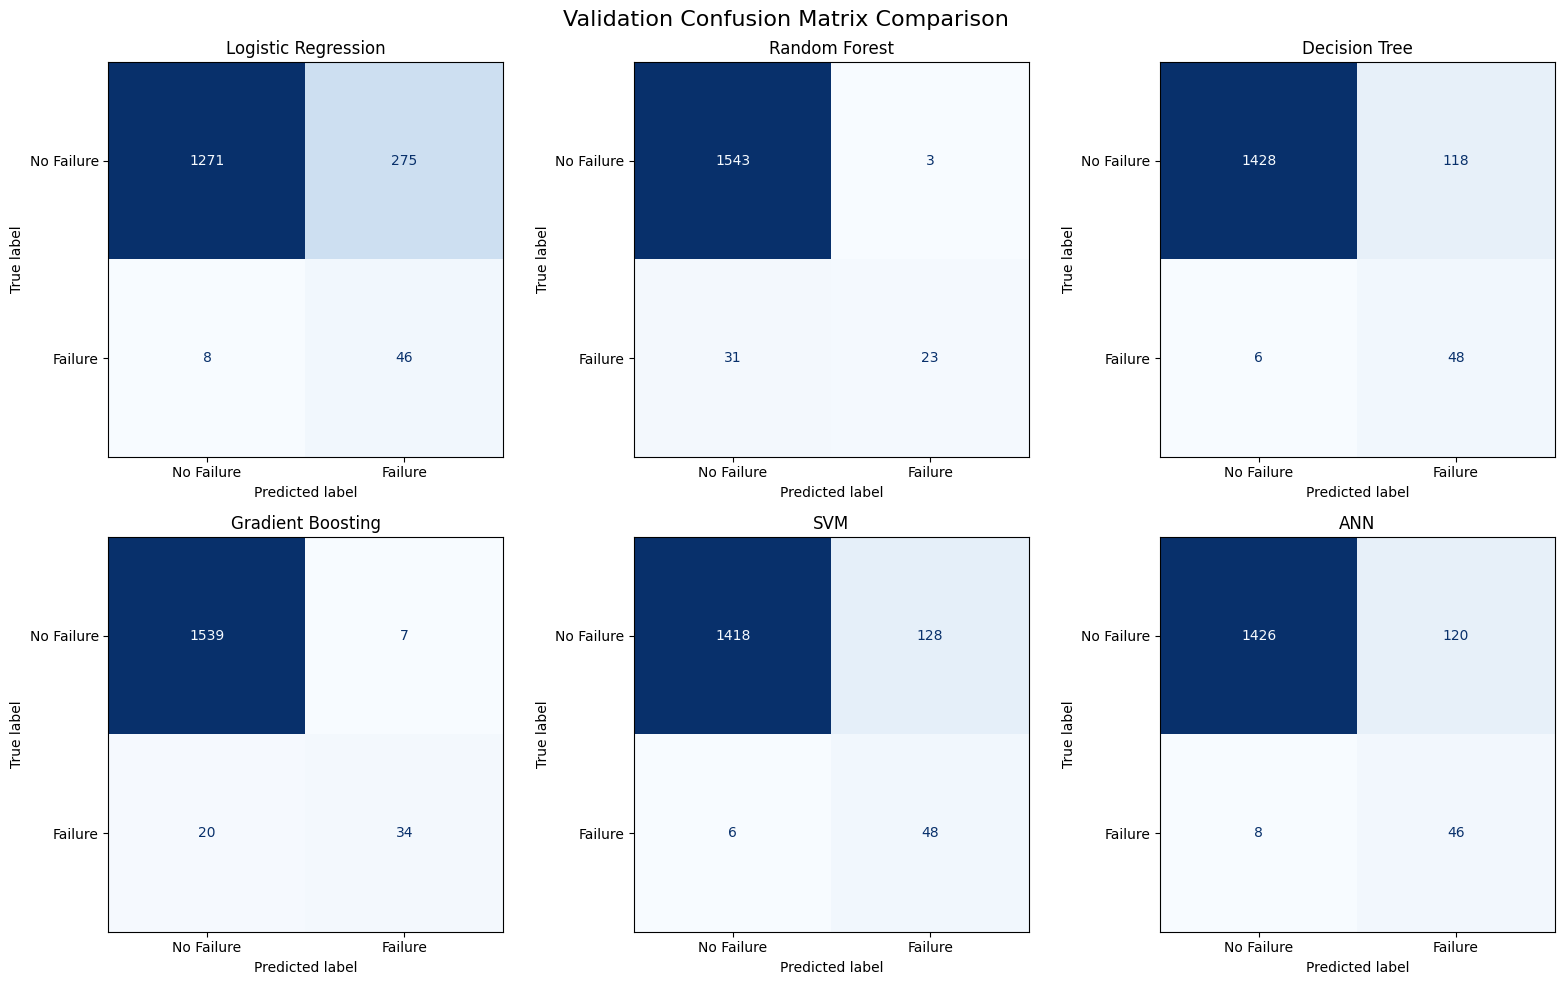

In [59]:

# Purpose: Compare confusion matrices of all trained models on validation data.

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

validation_predictions = {
    "Logistic Regression": logistic_model.predict(X_val_processed),
    "Random Forest": rf_model.predict(X_val_processed),
    "Decision Tree": dt_model.predict(X_val_processed),
    "Gradient Boosting": gb_model.predict(X_val_processed),
    "SVM": svm_model.predict(X_val_processed),
    "ANN": (ann_model.predict(X_val_processed, verbose=0).ravel() >= 0.5).astype(int)
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (model_name, predictions) in zip(
    axes.flatten(), validation_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        display_labels=["No Failure", "Failure"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(model_name)

plt.suptitle("Validation Confusion Matrix Comparison", fontsize=16)
plt.tight_layout()
plt.show()


### Confusion Matrix Interpretation

- **Logistic Regression:** Detected 46 out of 54 failures but generated 275 false alarms, resulting in low precision.
- **Random Forest:** Generated only 3 false alarms but missed 31 actual failures, resulting in low recall.
- **Decision Tree:** Detected 48 failures and missed only 6, but generated 118 false alarms.
- **Gradient Boosting:** Correctly identified 34 failures, missed 20 and generated only 7 false alarms. It demonstrated a balanced approach between failure detection and false alarms.
- **SVM:** Detected 48 failures and missed only 6, but generated 128 false alarms.
- **ANN:** Detected 46 failures and missed 8, while generating 120 false alarms.

### Conclusion

The confusion matrices reveal different trade-offs between detecting machine failures and avoiding unnecessary inspections.

Decision Tree and SVM achieved the highest failure detection at the default threshold, whereas Random Forest generated the fewest false alarms. Gradient Boosting provided a strong balance, making it a promising candidate for further evaluation.

However, the default threshold of 0.50 may not be optimal for predictive maintenance. Threshold optimization will help us identify a more suitable balance between missed failures and unnecessary inspections.

## 3.3 — False Positive and False Negative Analysis

,Model,False Positives,False Negatives,Total Errors
0,Logistic Regression,275,8,283
1,Random Forest,3,31,34
2,Decision Tree,118,6,124
3,Gradient Boosting,7,20,27
4,SVM,128,6,134
5,ANN,120,8,128


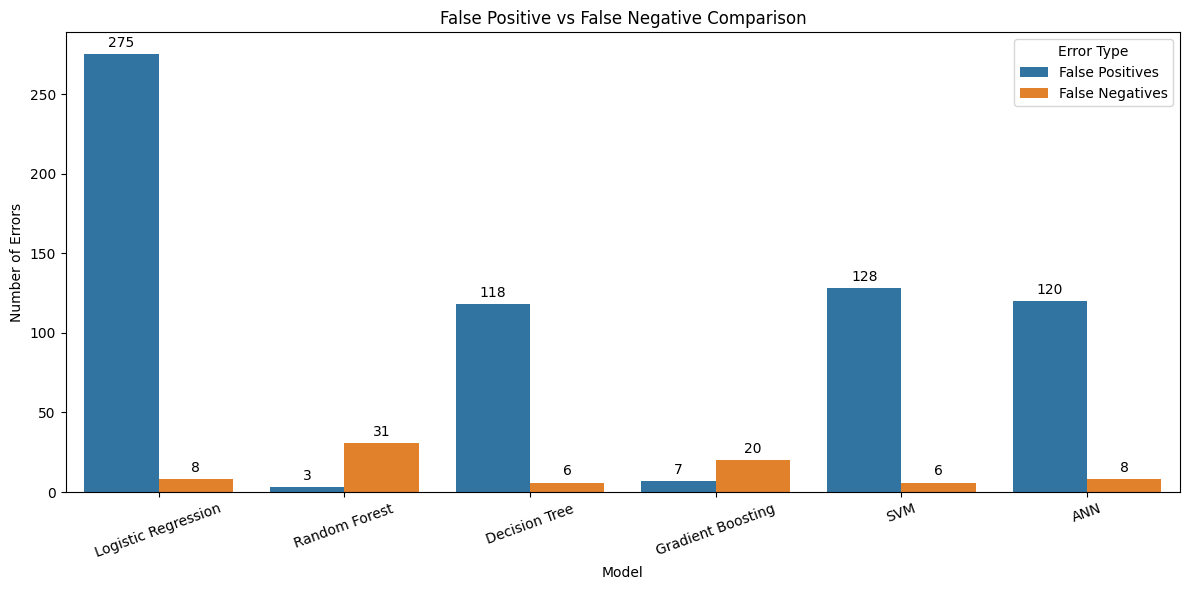

In [60]:

# Purpose: Compare false positives and false negatives across validation models.

from sklearn.metrics import confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

error_analysis = []

for model_name, predictions in validation_predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions
    ).ravel()

    error_analysis.append({
        "Model": model_name,
        "False Positives": fp,
        "False Negatives": fn,
        "Total Errors": fp + fn
    })

error_df = pd.DataFrame(error_analysis)

display(error_df)

# Visualize false positives and false negatives
error_plot = error_df.melt(
    id_vars="Model",
    value_vars=["False Positives", "False Negatives"],
    var_name="Error Type",
    value_name="Count"
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=error_plot,
    x="Model",
    y="Count",
    hue="Error Type"
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("False Positive vs False Negative Comparison")
plt.xlabel("Model")
plt.ylabel("Number of Errors")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### False Positive and False Negative Analysis

- **Logistic Regression:** Generated 275 false positives, indicating a high number of unnecessary inspection alerts, although it missed only 8 actual failures.
- **Random Forest:** Generated only 3 false positives but missed 31 actual failures, making it less suitable when detecting failures is the primary priority.
- **Decision Tree:** Missed only 6 actual failures but generated 118 false positives, creating a higher inspection workload.
- **Gradient Boosting:** Generated only 7 false positives and 20 false negatives, providing a good balance in terms of reducing unnecessary alerts and avoiding missed failures.
- **SVM:** Missed only 6 actual failures but generated 128 false positives.
- **ANN:** Missed 8 actual failures while generating 120 false positives.

### Business Interpretation

In predictive maintenance, a false positive may lead to an unnecessary inspection, whereas a false negative may allow a machine failure to go undetected, potentially causing unexpected downtime and production disruption.

Therefore, false negatives deserve particular attention. However, minimizing false negatives without considering false positives could create an excessive inspection workload.

### Conclusion

At the default classification threshold of 0.50, Gradient Boosting produced the fewest total errors (27), followed by Random Forest (34). However, Random Forest missed 31 actual failures compared with 20 for Gradient Boosting.

Gradient Boosting is therefore a promising candidate for further evaluation, but its threshold should be investigated to determine whether failure detection can be improved while maintaining a manageable number of false alarms.

## 3.4 — Decision Threshold Optimization

In [61]:

# Purpose: Find the best F1-score threshold for each model using validation probabilities.

import numpy as np
import pandas as pd

from sklearn.metrics import precision_score, recall_score, f1_score

# Generate validation probabilities
validation_probabilities = {
    "Logistic Regression": logistic_model.predict_proba(X_val_processed)[:, 1],
    "Random Forest": rf_model.predict_proba(X_val_processed)[:, 1],
    "Decision Tree": dt_model.predict_proba(X_val_processed)[:, 1],
    "Gradient Boosting": gb_model.predict_proba(X_val_processed)[:, 1],
    "SVM": svm_model.predict_proba(X_val_processed)[:, 1],
    "ANN": ann_model.predict(X_val_processed, verbose=0).ravel()
}

threshold_results = []

# Test thresholds from 0.10 to 0.90
thresholds = np.arange(0.10, 0.91, 0.05)

for model_name, probabilities in validation_probabilities.items():

    best_f1 = -1
    best_result = None

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_val, predictions, zero_division=0
        )

        recall = recall_score(
            y_val, predictions, zero_division=0
        )

        f1 = f1_score(
            y_val, predictions, zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1

            best_result = {
                "Model": model_name,
                "Optimal Threshold": round(threshold, 2),
                "Precision": precision,
                "Recall": recall,
                "F1-Score": f1
            }

    threshold_results.append(best_result)

threshold_comparison = pd.DataFrame(threshold_results)

display(
    threshold_comparison.sort_values(
        by="F1-Score",
        ascending=False
    ).reset_index(drop=True).round(4)
)


,Model,Optimal Threshold,Precision,Recall,F1-Score
0,Gradient Boosting,0.40,0.7551,0.6852,0.7184
1,Random Forest,0.35,0.8095,0.6296,0.7083
2,ANN,0.90,0.5429,0.7037,0.6129
3,SVM,0.25,0.5645,0.6481,0.6034
4,Decision Tree,0.80,0.4362,0.7593,0.5541
5,Logistic Regression,0.80,0.3367,0.6111,0.4342


### Threshold Optimization Analysis

- **Gradient Boosting:** Achieved the highest F1-score of 0.7184 at a threshold of 0.40, with 75.51% precision and 68.52% recall.
- **Random Forest:** Achieved the highest precision of 80.95% at a threshold of 0.35, but its recall was lower at 62.96%.
- **ANN:** Achieved an F1-score of 0.6129 at a threshold of 0.90, with 70.37% recall.
- **SVM:** Achieved 64.81% recall at a threshold of 0.25, with moderate precision.
- **Decision Tree:** Achieved the highest recall of 75.93% at a threshold of 0.80, but its precision was only 43.62%.
- **Logistic Regression:** Achieved the lowest F1-score of 0.4342, indicating weaker overall performance.

### Conclusion

Gradient Boosting achieved the highest F1-score (0.7184), providing the best precision–recall balance among the evaluated models at their respective optimized thresholds.

Random Forest is a strong alternative when reducing unnecessary inspection alerts is important, while Decision Tree offers higher failure detection at the cost of more false alarms.

Therefore, Gradient Boosting is selected as the leading candidate for further reliability evaluation, using a validation-selected threshold of 0.40.

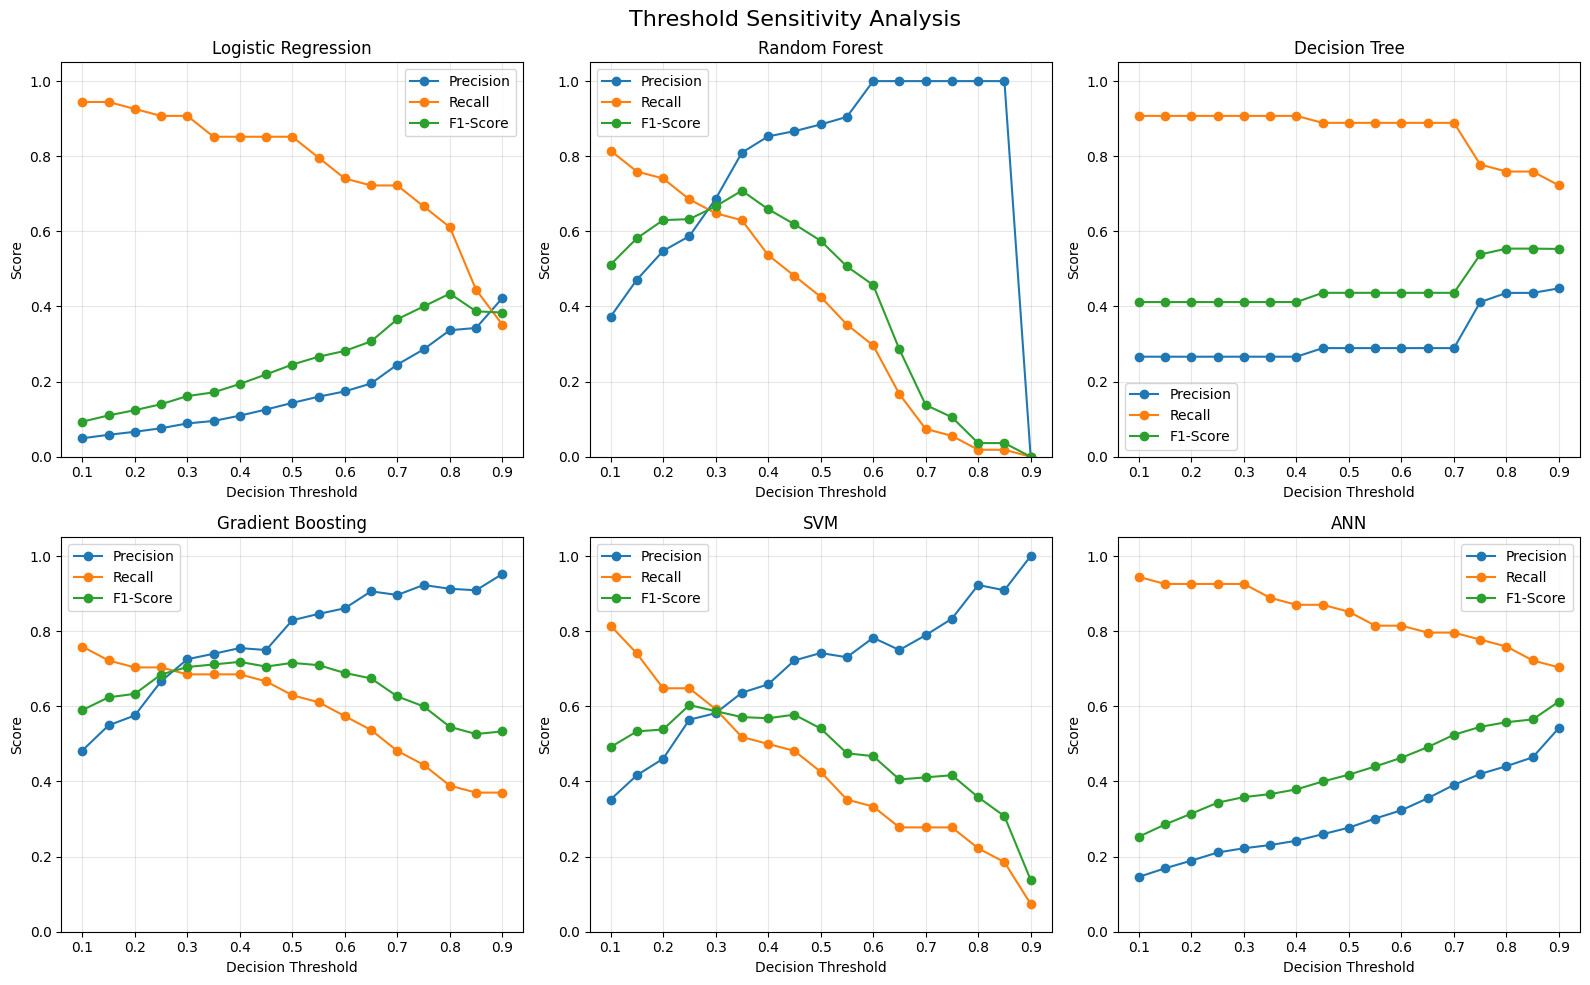

In [62]:

# Purpose: Visualize precision, recall and F1-score across classification thresholds.

from sklearn.metrics import precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (model_name, probabilities) in zip(
    axes.flatten(), validation_probabilities.items()
):
    precision_values = []
    recall_values = []
    f1_values = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        precision_values.append(
            precision_score(y_val, predictions, zero_division=0)
        )
        recall_values.append(
            recall_score(y_val, predictions, zero_division=0)
        )
        f1_values.append(
            f1_score(y_val, predictions, zero_division=0)
        )

    ax.plot(thresholds, precision_values, marker="o", label="Precision")
    ax.plot(thresholds, recall_values, marker="o", label="Recall")
    ax.plot(thresholds, f1_values, marker="o", label="F1-Score")

    ax.set_title(model_name)
    ax.set_xlabel("Decision Threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Threshold Sensitivity Analysis", fontsize=16)
plt.tight_layout()
plt.show()


### Threshold Sensitivity Analysis

- **Logistic Regression:** Precision gradually increases as the threshold increases, while recall decreases. Its F1-score improves towards higher thresholds but remains relatively low.
- **Random Forest:** Precision increases significantly with higher thresholds, while recall decreases sharply. This demonstrates the trade-off between reducing false alarms and detecting actual failures.
- **Decision Tree:** Recall remains relatively high across most thresholds, while precision improves at higher thresholds. Its best F1-score occurs at a threshold of 0.80.
- **Gradient Boosting:** Provides a relatively balanced precision–recall relationship. Its F1-score reaches its highest value at a threshold of 0.40.
- **SVM:** Precision improves with increasing thresholds, while recall decreases. Its F1-score reaches its highest value at a threshold of 0.25.
- **ANN:** Recall remains comparatively high across the tested thresholds, while precision gradually improves. Its F1-score reaches its highest value at a threshold of 0.90.

### Conclusion

Threshold sensitivity analysis confirms that the default threshold of 0.50 is not necessarily optimal for every model.

Gradient Boosting achieves the best validation F1-score of 0.7184 at a threshold of 0.40. Therefore, this threshold is selected as the leading candidate for independent test evaluation.

The final operational threshold will also require consideration of hypothetical inspection and missed-failure costs.

In [63]:

# Purpose: Compare all models using their validation-selected thresholds.

final_model_comparison = threshold_comparison.merge(
    model_comparison[["Model", "Accuracy", "ROC-AUC", "PR-AUC"]],
    on="Model",
    how="left"
)

final_model_comparison = final_model_comparison[
    [
        "Model",
        "Optimal Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ]
].sort_values("F1-Score", ascending=False)

display(final_model_comparison.round(4).reset_index(drop=True))


,Model,Optimal Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Gradient Boosting,0.40,0.9831,0.7551,0.6852,0.7184,0.9773,0.7668
1,Random Forest,0.35,0.9788,0.8095,0.6296,0.7083,0.9640,0.7347
2,ANN,0.90,0.9200,0.5429,0.7037,0.6129,0.9565,0.6910
3,SVM,0.25,0.9163,0.5645,0.6481,0.6034,0.9594,0.6308
4,Decision Tree,0.80,0.9225,0.4362,0.7593,0.5541,0.9084,0.4655
5,Logistic Regression,0.80,0.8231,0.3367,0.6111,0.4342,0.8927,0.4197


## 3.5 - Final Model Selection

Based on the validation results after threshold optimization:

- **Gradient Boosting** achieved the highest F1-score (0.7184), ROC-AUC (0.9773), PR-AUC (0.7668) and accuracy (98.31%) among the evaluated models.
- **Random Forest** achieved the highest precision (0.8095), making it suitable when minimizing unnecessary inspection alerts is important.
- **Decision Tree** achieved the highest recall (0.7593), identifying a larger proportion of actual failures, but with lower precision (0.4362).
- **ANN** achieved a recall of 0.7037 and F1-score of 0.6129, demonstrating reasonable failure detection performance.

### Selected Model: Gradient Boosting

Gradient Boosting is selected as the leading model because it provides the strongest overall validation performance, achieving an F1-score of 0.7184, precision of 0.7551 and recall of 0.6852 at a threshold of 0.40.

Its high ROC-AUC and PR-AUC also indicate strong discrimination between failure and non-failure cases.

The selected threshold of 0.40 will be carried forward for independent test evaluation. Final operational suitability will depend on the test results and maintenance cost considerations.

## 3.6 — Independent Test-Set Evaluation

Selected Model: Gradient Boosting
Decision Threshold: 0.4
Accuracy: 0.9850
Precision: 0.7879
Recall: 0.7647
F1-Score: 0.7761
ROC-AUC: 0.9638
PR-AUC: 0.7890

Confusion Matrix:
[[1918   14]
 [  16   52]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.79      0.76      0.78        68

    accuracy                           0.98      2000
   macro avg       0.89      0.88      0.88      2000
weighted avg       0.98      0.98      0.98      2000



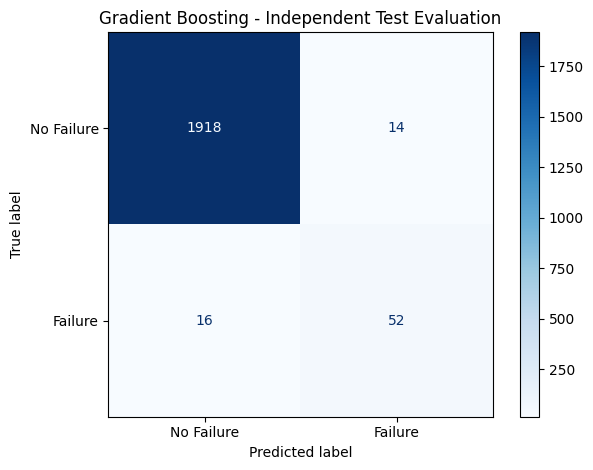

In [64]:

# Purpose: Evaluate the selected Gradient Boosting model on the independent test set.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Generate test probabilities
y_gb_test_prob = gb_model.predict_proba(X_test_processed)[:, 1]

# Apply validation-selected threshold
selected_threshold = 0.40

y_gb_test_pred = (
    y_gb_test_prob >= selected_threshold
).astype(int)

# Calculate evaluation metrics
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_gb_test_pred),
    "Precision": precision_score(y_test, y_gb_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_gb_test_pred, zero_division=0),
    "F1-Score": f1_score(y_test, y_gb_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_gb_test_prob),
    "PR-AUC": average_precision_score(y_test, y_gb_test_prob)
}

print("Selected Model: Gradient Boosting")
print("Decision Threshold:", selected_threshold)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_gb_test_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_gb_test_pred,
        target_names=["No Failure", "Failure"]
    )
)

# Visualize test confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_gb_test_pred,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)

plt.title("Gradient Boosting - Independent Test Evaluation")
plt.tight_layout()
plt.show()


### Independent Test Evaluation — Findings

The selected Gradient Boosting model was evaluated on the independent test dataset using the validation-selected threshold of 0.40.

- Achieved **98.50% accuracy** and **77.61% F1-score**.
- Achieved **78.79% precision** and **76.47% recall** for machine failure detection.
- Correctly identified 52 out of 68 actual failures.
- Missed 16 actual failures and generated 14 false-positive alerts.
- Achieved a ROC-AUC of 0.9638 and PR-AUC of 0.7890.

Compared with validation performance, the test F1-score and recall improved, while ROC-AUC decreased slightly. The results show no obvious performance deterioration on this particular test split.

### Conclusion

Gradient Boosting demonstrated promising performance on the independent test dataset. Its ability to identify failures while maintaining a relatively low number of false alarms makes it a suitable candidate for the predictive maintenance use case.

However, the model still misses some actual failures. Additional validation on real-world operational data is necessary before deployment.

## 3.7 — Hypothetical Maintenance Cost Analysis

In [65]:

# Purpose: Estimate hypothetical maintenance costs from test-set prediction errors.

# Hypothetical cost assumptions
cost_per_false_positive = 2000
cost_per_false_negative = 50000

# Extract confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_gb_test_pred
).ravel()

# Calculate individual costs
false_positive_cost = fp * cost_per_false_positive
false_negative_cost = fn * cost_per_false_negative

# Calculate total estimated cost
total_maintenance_cost = (
    false_positive_cost + false_negative_cost
)

cost_analysis = pd.DataFrame({
    "Error Type": ["False Positive", "False Negative"],
    "Error Count": [fp, fn],
    "Cost Per Error (INR)": [
        cost_per_false_positive,
        cost_per_false_negative
    ],
    "Total Cost (INR)": [
        false_positive_cost,
        false_negative_cost
    ]
})

display(cost_analysis)

print(f"Total Hypothetical Maintenance Cost: ₹{total_maintenance_cost:,.2f}")
print(f"False Positive Cost: ₹{false_positive_cost:,.2f}")
print(f"False Negative Cost: ₹{false_negative_cost:,.2f}")


,Error Type,Error Count,Cost Per Error (INR),Total Cost (INR)
0,False Positive,14,2000,28000
1,False Negative,16,50000,800000


Total Hypothetical Maintenance Cost: ₹828,000.00
False Positive Cost: ₹28,000.00
False Negative Cost: ₹800,000.00


### Hypothetical Maintenance Cost — Observations

- **False Positive Cost:** ₹28,000 from 14 unnecessary inspection alerts.
- **False Negative Cost:** ₹8,00,000 from 16 missed machine failures.
- **Total Estimated Cost:** ₹8,28,000.

False-negative costs account for approximately 96.62% of the total estimated cost, demonstrating the financial impact of missed machine failures under our assumed cost structure.

### Conclusion

The hypothetical cost analysis indicates that missed machine failures have a substantially greater financial impact than unnecessary inspections.

Therefore, the predictive maintenance system should prioritize identifying actual failure cases while maintaining a manageable inspection workload. The selected threshold of 0.40 will be compared against alternative thresholds to determine whether further cost reduction is possible.

## 3.8 — Cost-Based Threshold Optimization

In [66]:

# Purpose: Identify the cost-effective decision threshold for Gradient Boosting.

from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

# Hypothetical cost assumptions
cost_per_fp = 2000
cost_per_fn = 50000

# Use validation probabilities only
gb_val_prob = validation_probabilities["Gradient Boosting"]

# Evaluate thresholds
cost_thresholds = np.arange(0.10, 0.91, 0.05)

cost_results = []

for threshold in cost_thresholds:

    predictions = (gb_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions
    ).ravel()

    fp_cost = fp * cost_per_fp
    fn_cost = fn * cost_per_fn

    total_cost = fp_cost + fn_cost

    cost_results.append({
        "Threshold": round(threshold, 2),
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "FP Cost (INR)": fp_cost,
        "FN Cost (INR)": fn_cost,
        "Total Cost (INR)": total_cost
    })

cost_threshold_comparison = pd.DataFrame(cost_results)

display(
    cost_threshold_comparison.sort_values(
        "Total Cost (INR)"
    ).reset_index(drop=True).round(4)
)


,Threshold,True Positives,False Positives,False Negatives,Precision,Recall,F1-Score,FP Cost (INR),FN Cost (INR),Total Cost (INR)
0,0.10,41,44,13,0.4824,0.7593,0.5899,88000,650000,738000
1,0.15,39,32,15,0.5493,0.7222,0.6240,64000,750000,814000
2,0.25,38,19,16,0.6667,0.7037,0.6847,38000,800000,838000
3,0.20,38,28,16,0.5758,0.7037,0.6333,56000,800000,856000
4,0.40,37,12,17,0.7551,0.6852,0.7184,24000,850000,874000
5,0.35,37,13,17,0.7400,0.6852,0.7115,26000,850000,876000
6,0.30,37,14,17,0.7255,0.6852,0.7048,28000,850000,878000
7,0.45,36,12,18,0.7500,0.6667,0.7059,24000,900000,924000
8,0.50,34,7,20,0.8293,0.6296,0.7158,14000,1000000,1014000
9,0.55,33,6,21,0.8462,0.6111,0.7097,12000,1050000,1062000


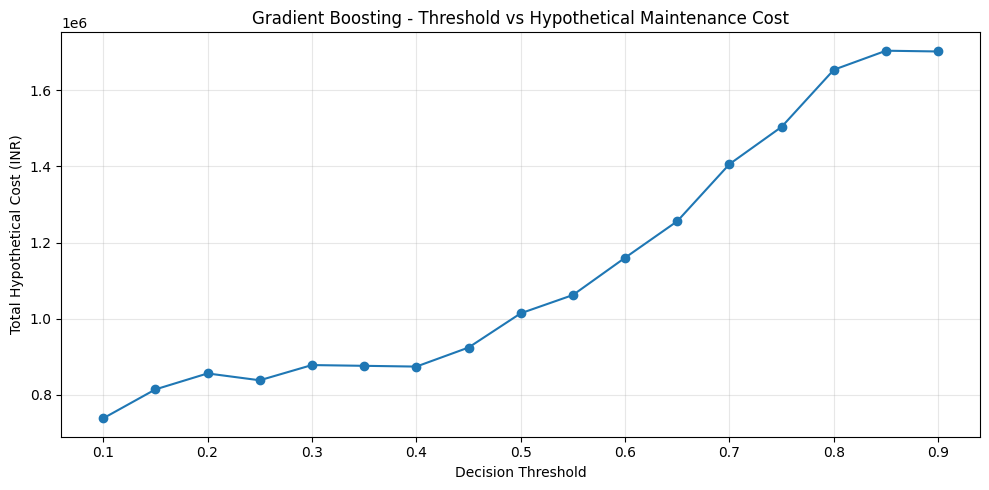

In [67]:

# Purpose: Visualize how hypothetical maintenance cost changes with the threshold.

plt.figure(figsize=(10, 5))

plt.plot(
    cost_threshold_comparison["Threshold"],
    cost_threshold_comparison["Total Cost (INR)"],
    marker="o"
)

plt.title("Gradient Boosting - Threshold vs Hypothetical Maintenance Cost")
plt.xlabel("Decision Threshold")
plt.ylabel("Total Hypothetical Cost (INR)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Cost-Based Threshold Optimization — Findings

The cost-based threshold analysis was conducted using validation probabilities and hypothetical costs of ₹2,000 per false positive and ₹50,000 per false negative.

- The lowest estimated cost among the tested thresholds was ₹7,38,000 at a threshold of 0.10.
- At this threshold, the model generated 44 false positives and 13 false negatives.
- The recall increased to 75.93%, compared with 68.52% at the F1-optimal threshold of 0.40.
- The F1-score decreased from 0.7184 to 0.5899 because the lower threshold generated more false-positive predictions.
- The estimated cost decreased by ₹1,36,000 compared with the threshold of 0.40.

### Conclusion

The experiment demonstrates that the optimal classification threshold depends on the business objective.

The threshold of 0.40 provides the best F1-score, whereas 0.10 minimizes the estimated hypothetical maintenance cost under the selected cost assumptions.

Since missed machine failures are assumed to be significantly more expensive than unnecessary inspections, the threshold of 0.10 becomes the preferred candidate for cost-sensitive predictive maintenance evaluation.

However, the final recommendation must also consider inspection capacity, operational safety and the independent test-set performance.

In [68]:

# Purpose: Evaluate the validation-selected cost-optimal threshold on test data.

cost_optimal_threshold = 0.10

y_gb_cost_pred = (
    y_gb_test_prob >= cost_optimal_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_gb_cost_pred
).ravel()

test_cost = (
    fp * cost_per_fp +
    fn * cost_per_fn
)

print("Cost-Optimal Threshold:", cost_optimal_threshold)
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nPrecision:", round(
    precision_score(y_test, y_gb_cost_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_gb_cost_pred, zero_division=0), 4
))
print("F1-Score:", round(
    f1_score(y_test, y_gb_cost_pred, zero_division=0), 4
))

print(f"\nHypothetical Test Maintenance Cost: ₹{test_cost:,.2f}")


Cost-Optimal Threshold: 0.1
True Negatives: 1876
False Positives: 56
False Negatives: 14
True Positives: 54

Precision: 0.4909
Recall: 0.7941
F1-Score: 0.6067

Hypothetical Test Maintenance Cost: ₹812,000.00


### Cost-Optimal Threshold — Independent Test Evaluation

The threshold of 0.10, selected using validation data, was evaluated on the independent test dataset.

- Achieved 79.41% recall, compared with 76.47% at the threshold of 0.40.
- Detected 54 out of 68 actual machine failures.
- Reduced false negatives from 16 to 14.
- Generated 56 false positives, compared with 14 at the threshold of 0.40.
- Precision decreased from 78.79% to 49.09%.
- F1-score decreased from 77.61% to 60.67%.
- The hypothetical test maintenance cost decreased from ₹8,28,000 to ₹8,12,000.

### Conclusion

The cost-optimal threshold improved failure detection and reduced the hypothetical maintenance cost by ₹16,000 on the test dataset.

However, this improvement required 42 additional inspection alerts and resulted in lower precision and F1-score.

Therefore, threshold selection involves a trade-off between failure detection, inspection workload and estimated maintenance costs. The threshold of 0.10 is preferable under the assumed cost structure, provided the organization can accommodate the increased inspection workload.

The cost estimates are illustrative and should be recalculated using actual operational costs before deployment.

## 3.9 — Final Operational Threshold Recommendation

### Final Operational Threshold Recommendation

The Gradient Boosting model provides two possible operational strategies based on different business priorities.

**Strategy 1: Balanced Approach — Threshold 0.40**

- Achieved 78.79% precision and 76.47% recall on the independent test dataset.
- Generated 14 false-positive alerts and missed 16 actual failures.
- Produced a hypothetical maintenance cost of ₹8,28,000.
- Suitable when inspection resources are limited and unnecessary maintenance alerts must be controlled.

**Strategy 2: Cost-Sensitive Approach — Threshold 0.10**

- Achieved 49.09% precision and 79.41% recall on the independent test dataset.
- Generated 56 false-positive alerts and missed 14 actual failures.
- Produced a hypothetical maintenance cost of ₹8,12,000.
- Suitable when identifying more potential failures is a priority and sufficient inspection capacity is available.

**Final Decision:**

The threshold of 0.10 is the preferred candidate under the assumed cost structure because it produces a lower estimated maintenance cost and detects more actual failures.

However, the threshold of 0.40 remains a practical alternative when inspection capacity and alert volume are important operational constraints.

The final production threshold should be determined using actual inspection costs, downtime expenses, maintenance capacity and real-world validation data.

The model should initially operate as a decision-support system, with maintenance personnel reviewing alerts before taking action.

# Phase 4 — Research and Controlled Experimentation

## 4.1 Research Question & Hypothesis

**Research Question:**

Can an Artificial Neural Network (ANN) outperform traditional Machine Learning models in predicting machine failures?

**Null Hypothesis (H0):** ANN does not demonstrate better predictive performance than traditional ML models.

**Alternative Hypothesis (H1):** ANN demonstrates better predictive performance than traditional ML models.

**Evaluation Metrics:**
- Precision
- Recall
- F1-Score
- ROC-AUC
- PR-AUC

Recall and PR-AUC receive particular attention because machine failures are rare events, and missing an actual failure can lead to unexpected downtime.



## 4.2 ANN vs Traditional ML Comparison

The baseline ANN was compared with traditional ML models using validation data at the default classification threshold of 0.50.

| Model | Precision | Recall | F1-Score | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|
| Gradient Boosting | 0.8293 | 0.6296 | 0.7158 | 0.9773 | 0.7668 |
| Random Forest | 0.8846 | 0.4259 | 0.5750 | 0.9640 | 0.7347 |
| ANN | 0.2771 | 0.8519 | 0.4182 | 0.9565 | 0.6910 |

**Initial Observation:**

- ANN achieved higher Recall than Gradient Boosting and Random Forest at the 0.50 threshold.
- Gradient Boosting achieved better F1-Score, ROC-AUC and PR-AUC.
- ANN identified more actual failures but generated more false-positive predictions.

**Initial Finding:** The baseline ANN did not outperform the strongest traditional ML model overall, although it demonstrated stronger failure detection at the default threshold.



## 4.3 Controlled Experiment Design

**Experiment Objective:**

Evaluate the impact of changing the ANN learning rate on machine failure prediction.

We compare two configurations:

| Parameter | Baseline ANN | Experimental ANN |
|---|---|---|
| Architecture | 64 → 32 → 1 | 64 → 32 → 1 |
| Optimizer | Adam | Adam |
| Learning Rate | 0.001 | 0.0001 |
| Batch Size | 32 | 32 |
| Epochs | 50 | 50 |
| Class Weights | Balanced | Balanced |
| Random Seeds | 42, 52, 62 | 42, 52, 62 |

**Controlled Variable:** Learning rate.

All other parameters, training data, validation data and evaluation metrics remain unchanged.

Each configuration will be trained three times using different random seeds to examine performance consistency.


## 4.4 Repeated ANN Experiments

In [72]:
# Purpose: Compare baseline and experimental ANN performance across three random seeds.

import tensorflow as tf
import numpy as np
import pandas as pd

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

seeds = [42, 52, 62]

learning_rates = {
    "Baseline": 0.001,
    "Experimental": 0.0001
}

class_weights = {
    0: 0.5175481158013909,
    1: 14.746543778801843
}

repeated_results = []
repeated_models = {}

for experiment_name, learning_rate in learning_rates.items():

    for seed in seeds:

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        model = Sequential([
            Input(shape=(X_train_processed.shape[1],)),
            Dense(64, activation="relu"),
            Dense(32, activation="relu"),
            Dense(1, activation="sigmoid")
        ])

        model.compile(
            optimizer=Adam(learning_rate=learning_rate),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        history = model.fit(
            X_train_processed,
            y_train,
            validation_data=(X_val_processed, y_val),
            epochs=50,
            batch_size=32,
            class_weight=class_weights,
            verbose=0
        )

        val_probabilities = model.predict(
            X_val_processed, verbose=0
        ).ravel()

        val_predictions = (val_probabilities >= 0.5).astype(int)

        repeated_results.append({
            "Experiment": experiment_name,
            "Learning Rate": learning_rate,
            "Seed": seed,
            "Accuracy": accuracy_score(y_val, val_predictions),
            "Precision": precision_score(y_val, val_predictions, zero_division=0),
            "Recall": recall_score(y_val, val_predictions, zero_division=0),
            "F1-Score": f1_score(y_val, val_predictions, zero_division=0),
            "ROC-AUC": roc_auc_score(y_val, val_probabilities),
            "PR-AUC": average_precision_score(y_val, val_probabilities),
            "Final Train Loss": history.history["loss"][-1],
            "Final Validation Loss": history.history["val_loss"][-1]
        })

        repeated_models[(experiment_name, seed)] = model

        print(f"{experiment_name} | Seed {seed} completed")

repeated_results_df = pd.DataFrame(repeated_results)

display(repeated_results_df.round(4))

Baseline | Seed 42 completed
Baseline | Seed 52 completed
Baseline | Seed 62 completed
Experimental | Seed 42 completed
Experimental | Seed 52 completed
Experimental | Seed 62 completed


,Experiment,Learning Rate,Seed,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Final Train Loss,Final Validation Loss
0,Baseline,0.0010,42,0.9200,0.2771,0.8519,0.4182,0.9565,0.6910,0.1146,0.1970
1,Baseline,0.0010,52,0.9469,0.3719,0.8333,0.5143,0.9508,0.6447,0.1147,0.1510
2,Baseline,0.0010,62,0.9225,0.2812,0.8333,0.4206,0.9546,0.6883,0.1273,0.1862
3,Experimental,0.0001,42,0.8794,0.1965,0.8333,0.3180,0.9421,0.5961,0.2631,0.2922
4,Experimental,0.0001,52,0.8812,0.1991,0.8333,0.3214,0.9435,0.5842,0.2590,0.2907
5,Experimental,0.0001,62,0.8756,0.1941,0.8519,0.3162,0.9513,0.6160,0.2514,0.2725


## 4.5 Experiment Results — Statistical Summary

In [73]:
# Purpose: Calculate mean and standard deviation across repeated ANN experiments.

metrics_to_compare = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC",
    "Final Train Loss",
    "Final Validation Loss"
]

repeated_summary = (
    repeated_results_df
    .groupby("Experiment")[metrics_to_compare]
    .agg(["mean", "std"])
)

display(repeated_summary.round(4))

Accuracy         Precision          Recall         F1-Score  \
                 mean     std      mean     std    mean     std     mean   
Experiment                                                                 
Baseline       0.9298  0.0148    0.3101  0.0536  0.8395  0.0107   0.4510   
Experimental   0.8788  0.0029    0.1966  0.0025  0.8395  0.0107   0.3185   

                     ROC-AUC          PR-AUC        Final Train Loss          \
                 std    mean     std    mean    std             mean     std   
Experiment                                                                     
Baseline      0.0548  0.9540  0.0029  0.6747  0.026           0.1189  0.0073   
Experimental  0.0027  0.9456  0.0049  0.5988  0.016           0.2578  0.0059   

             Final Validation Loss         
                              mean    std  
Experiment                                 
Baseline                    0.1781  0.024  
Experimental                0.2851  0.011


## 4.6 Results Interpretation

The repeated experiments across three random seeds produced the following observations:

- **Accuracy:** Baseline ANN achieved a higher mean accuracy (0.9298) compared to the experimental ANN (0.8788).
- **Precision:** Baseline ANN achieved better precision (0.3101 vs 0.1966), indicating fewer false-positive predictions.
- **Recall:** Both configurations achieved the same mean recall (0.8395), indicating similar failure detection capability.
- **F1-Score:** Baseline ANN achieved a higher mean F1-score (0.4510 vs 0.3185).
- **ROC-AUC:** Baseline ANN performed better (0.9540 vs 0.9456).
- **PR-AUC:** Baseline ANN achieved a higher score (0.6747 vs 0.5988).
- **Loss:** Baseline ANN achieved lower training and validation losses, indicating better convergence within 50 epochs.

**Variability Analysis:**

The standard deviations across three runs were relatively small for most metrics. The experimental ANN showed more consistent Accuracy and Precision, but consistently lower performance.

**Conclusion:** The learning rate of 0.001 provided better predictive performance within the selected experimental setup. Reducing the learning rate to 0.0001 did not improve ANN performance within 50 epochs.

Although the standard deviations were relatively small for most metrics, three runs provide limited evidence about performance variability. Therefore, the observed differences should not be treated as statistically significant improvements.



## 4.7 Hypothesis Evaluation

The experimental findings were evaluated against the research hypotheses.

**Evaluation of H0 (Null Hypothesis):**

The baseline ANN did not demonstrate better overall predictive performance than the strongest traditional ML model, Gradient Boosting.

**Evaluation of H1 (Alternative Hypothesis):**

The results do not support H1, as Gradient Boosting achieved better F1-Score (0.7158), ROC-AUC (0.9773) and PR-AUC (0.7668) compared to the baseline ANN.

However, ANN achieved higher Recall (0.8519) than Gradient Boosting (0.6296) at the default classification threshold of 0.50, demonstrating its ability to identify more actual machine failures.

**Controlled Experiment Findings:**

- The baseline learning rate (0.001) performed better than the experimental learning rate (0.0001) across most evaluation metrics.
- Both configurations achieved the same mean Recall of 0.8395 across three runs.
- The baseline ANN achieved a higher mean F1-Score (0.4510) and PR-AUC (0.6747).
- The observed differences indicate that reducing the learning rate did not improve performance within the selected 50-epoch experimental setup.

**Final Conclusion:**

The available evidence favors Gradient Boosting over the baseline ANN for overall predictive performance in this dataset. However, ANN demonstrated competitive failure detection capability in terms of Recall.

The repeated experiments provide useful evidence of performance consistency, but three runs are insufficient to establish statistical significance. These findings apply to the selected dataset, model configurations and experimental conditions; they do not establish that traditional ML models are universally superior to ANN.
